<a href="https://www.kaggle.com/code/bevismathewthomas/finalyearproj?scriptVersionId=358280341" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
!git clone https://github.com/multimediaFor/MPC.git /kaggle/working/MPC
%cd /kaggle/working/MPC/CATNet_dataset_train/stage2

Cloning into '/kaggle/working/MPC'...
remote: Enumerating objects: 99, done.
remote: Counting objects: 100% (99/99), done.
remote: Compressing objects: 100% (77/77), done.
remote: Total 99 (delta 27), reused 68 (delta 12), pack-reused 0 (from 0)
Receiving objects: 100% (99/99), 510.58 KiB | 2.57 MiB/s, done.
Resolving deltas: 100% (27/27), done.
/kaggle/working/MPC/CATNet_dataset_train/stage2


In [2]:
!pip install -q albumentations==1.3.1 fvcore opencv-python opencv-python-headless torchsummary gdown scikit-learn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 1.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 1.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 125.7/125.7 kB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.6/129.6 kB 7.6 MB/s eta 0:00:00


In [3]:
import os

# List all directories under Kaggle input to verify dataset location
for root, dirs, files in os.walk('/kaggle/input'):
    print(root)

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/divg07
/kaggle/input/datasets/divg07/casia-20-image-tampering-detection-dataset
/kaggle/input/datasets/divg07/casia-20-image-tampering-detection-dataset/CASIA2
/kaggle/input/datasets/divg07/casia-20-image-tampering-detection-dataset/CASIA2/CASIA 2 Groundtruth
/kaggle/input/datasets/divg07/casia-20-image-tampering-detection-dataset/CASIA2/Au
/kaggle/input/datasets/divg07/casia-20-image-tampering-detection-dataset/CASIA2/Tp


In [4]:
import os
print("Tp exists:", os.path.isdir('/content/CASIA2_extracted/CASIA2/Tp'))
print("Au exists:", os.path.isdir('/content/CASIA2_extracted/CASIA2/Au'))
print("GT exists:", os.path.isdir('/content/CASIA2_extracted/CASIA2/CASIA 2 Groundtruth'))

Tp exists: False
Au exists: False
GT exists: False


In [5]:
import os

# Set dataset root to Kaggle's input directory
CASIA2_ROOT = '/kaggle/input'
TP_DIR = os.path.join(CASIA2_ROOT, 'Tp')
AU_DIR = os.path.join(CASIA2_ROOT, 'Au')
GT_DIR = os.path.join(CASIA2_ROOT, 'CASIA 2 Groundtruth')

In [6]:
import os

def find_dataset_dirs():
    tp_dir, gt_dir = None, None
    for root, dirs, _ in os.walk('/kaggle/input'):
        dirs_lower = {d.lower(): d for d in dirs}
        if 'tp' in dirs_lower and tp_dir is None:
            tp_dir = os.path.join(root, dirs_lower['tp'])
        gt_cands = [d for d in dirs if 'groundtruth' in d.lower() or 'gt' in d.lower()]
        if gt_cands and gt_dir is None:
            gt_dir = os.path.join(root, gt_cands[0])
    return tp_dir, gt_dir

TP_DIR, GT_DIR = find_dataset_dirs()

print("Auto-detected TP_DIR:", TP_DIR)
print("Auto-detected GT_DIR:", GT_DIR)

assert TP_DIR is not None and os.path.exists(TP_DIR), "Could not locate 'Tp' folder in /kaggle/input"
assert GT_DIR is not None and os.path.exists(GT_DIR), "Could not locate Groundtruth folder in /kaggle/input"

Auto-detected TP_DIR: /kaggle/input/datasets/divg07/casia-20-image-tampering-detection-dataset/CASIA2/Tp
Auto-detected GT_DIR: /kaggle/input/datasets/divg07/casia-20-image-tampering-detection-dataset/CASIA2/CASIA 2 Groundtruth


In [7]:
!ls /content

sample_data


In [8]:
import glob
import numpy as np

os.makedirs('flist', exist_ok=True)

pairs = []
unmatched = 0
for mask_path in sorted(glob.glob(os.path.join(GT_DIR, '*_gt.png'))):
    stem = os.path.basename(mask_path)[:-len('_gt.png')]
    candidates = glob.glob(os.path.join(TP_DIR, stem + '.*'))
    if candidates:
        pairs.append((candidates[0], mask_path))
    else:
        unmatched += 1

print(f'Matched pairs: {len(pairs)}   Unmatched masks: {unmatched}')
assert len(pairs) > 0, 'No pairs matched — double-check CASIA2_ROOT / TP_DIR.'

# hold out a random test split (e.g. 500 images) so numbers reflect held-out performance
import random
random.seed(0)
random.shuffle(pairs)
TEST_N = min(500, len(pairs))
test_pairs = pairs[:TEST_N]

flist_path = 'flist/CASIA2_test_%d.npy' % len(test_pairs)
np.save(flist_path, np.array(test_pairs))
print('Saved flist ->', flist_path, '(', len(test_pairs), 'pairs )')

Matched pairs: 4981   Unmatched masks: 141
Saved flist -> flist/CASIA2_test_500.npy ( 500 pairs )


In [9]:
%cd /content/MPC/CATNet_dataset_train/stage2
import os
os.makedirs('weights', exist_ok=True)

# MPC_CATNet_stage2_weights.pth (generalization checkpoint)
!gdown --id 1vXDvrTVizINKcR_MgdA_uuTWcB3I4HdI -O weights/MPC_CATNet_stage2_weights.pth

# MPC_CASIAv2_stage2_weights.pth (trained on CASIA2 itself — reference only)
!gdown --id 148gv5ovxrQR0QZL2rB3Jt-9lwAS_AH0d -O weights/MPC_CASIAv2_stage2_weights.pth

!ls -lh weights/

[Errno 2] No such file or directory: '/content/MPC/CATNet_dataset_train/stage2'
/kaggle/working/MPC/CATNet_dataset_train/stage2
/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1vXDvrTVizINKcR_MgdA_uuTWcB3I4HdI
From (redirected): https://drive.google.com/uc?id=1vXDvrTVizINKcR_MgdA_uuTWcB3I4HdI&confirm=t&uuid=ae07334b-23c7-4698-b288-5c708bb726fe
To: /kaggle/working/MPC/CATNet_dataset_train/stage2/weights/MPC_CATNet_stage2_weights.pth
100%|████████████████████████████████████████| 183M/183M [00:05<00:00, 30.9MB/s]
/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (origi

In [10]:
import torch
import torch.nn as nn
import logging as logger
from model import MyModel

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)

class MPC(nn.Module):
    def __init__(self, weight_path):
        super(MPC, self).__init__()
        self.cur_net = MyModel().to(device)
        self._load(self.cur_net, weight_path)
        self.cur_net.eval()

    def process(self, Ii):
        with torch.no_grad():
            Fo = self.cur_net(Ii)
        return torch.sigmoid(Fo)

    def _load(self, model, path):
        weights = torch.load(path, map_location=device)
        model_state_dict = model.state_dict()
        loaded, missing, mismatched = [], [], []
        for name, param in weights.items():
            if name in model_state_dict:
                if param.shape == model_state_dict[name].shape:
                    model_state_dict[name].copy_(param)
                    loaded.append(name)
                else:
                    mismatched.append(name)
            else:
                missing.append(name)
        model.load_state_dict(model_state_dict)
        print(f'[{os.path.basename(path)}] loaded {len(loaded)} layers, '
              f'{len(missing)} missing, {len(mismatched)} shape-mismatched.')

model_generalization = MPC('weights/MPC_CATNet_stage2_weights.pth')
model_casia_trained   = MPC('weights/MPC_CASIAv2_stage2_weights.pth')

Using device: cuda
[MPC_CATNet_stage2_weights.pth] loaded 2264 layers, 0 missing, 0 shape-mismatched.
[MPC_CASIAv2_stage2_weights.pth] loaded 2262 layers, 7 missing, 2 shape-mismatched.


In [11]:
import cv2
import numpy as np
from sklearn.metrics import f1_score, accuracy_score

INPUT_SIZE = 512

def thresholding(x, thres=0.5):
    x = x.copy()
    x[x <= int(thres * 255)] = 0
    x[x > int(thres * 255)] = 255
    return x

def metric_iou(pred, gt):
    if pred.shape != gt.shape:
        pred = cv2.resize(pred.astype(np.uint8), (gt.shape[1], gt.shape[0]), interpolation=cv2.INTER_NEAREST)
    intersection = np.logical_and(pred, gt)
    union = np.logical_or(pred, gt)
    if union.sum() == 0:
        return 1.0
    return intersection.sum() / (union.sum() + 1e-6)

def load_pair(img_path, mask_path):
    img = cv2.imread(img_path)[..., ::-1]
    H, W = img.shape[:2]
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    mask = cv2.resize(mask, (W, H), interpolation=cv2.INTER_NEAREST)   # <-- ADD THIS LINE
    mask = thresholding(mask)
    img_r = cv2.resize(img, (INPUT_SIZE, INPUT_SIZE)).astype('float32') / 255.
    tensor = torch.from_numpy(img_r).permute(2, 0, 1).unsqueeze(0).float().to(device)
    return tensor, mask, (H, W), img

@torch.no_grad()
def evaluate(model, pairs, max_images=None, tag=''):
    n = len(pairs) if max_images is None else min(max_images, len(pairs))
    f1s, ious, accs = [], [], []
    for img_path, mask_path in pairs[:n]:
        tensor, gt_mask, (H, W), _ = load_pair(img_path, mask_path)
        pred = model.process(tensor)                       # [1,1,h,w] in (0,1)
        pred = pred.squeeze().cpu().numpy() * 255.
        pred_resized = cv2.resize(pred, (W, H))
        pred_bin = thresholding(pred_resized)

        gt_flat = (gt_mask.flatten() / 255.).astype(np.uint8)
        pred_flat = (pred_bin.flatten() / 255.).astype(np.uint8)

        f1s.append(f1_score(gt_flat, pred_flat, zero_division=1))
        accs.append(accuracy_score(gt_flat, pred_flat))
        ious.append(metric_iou(pred_bin / 255., gt_mask / 255.))

    print(f'--- {tag} (n={n}) ---')
    print(f'  Mean F1 Score      : {np.mean(f1s):.4f}')
    print(f'  Mean IoU           : {np.mean(ious):.4f}')
    print(f'  Mean Pixel Accuracy: {np.mean(accs):.4f}')
    return np.mean(f1s), np.mean(ious), np.mean(accs)

print('Evaluating on', len(test_pairs), 'held-out CASIA2 tampered images...\n')
gen_f1, gen_iou, gen_acc = evaluate(model_generalization, test_pairs, tag='MPC_CATNet_stage2_weights (generalization)')


Evaluating on 500 held-out CASIA2 tampered images...

--- MPC_CATNet_stage2_weights (generalization) (n=500) ---
  Mean F1 Score      : 0.7360
  Mean IoU           : 0.6756
  Mean Pixel Accuracy: 0.9638


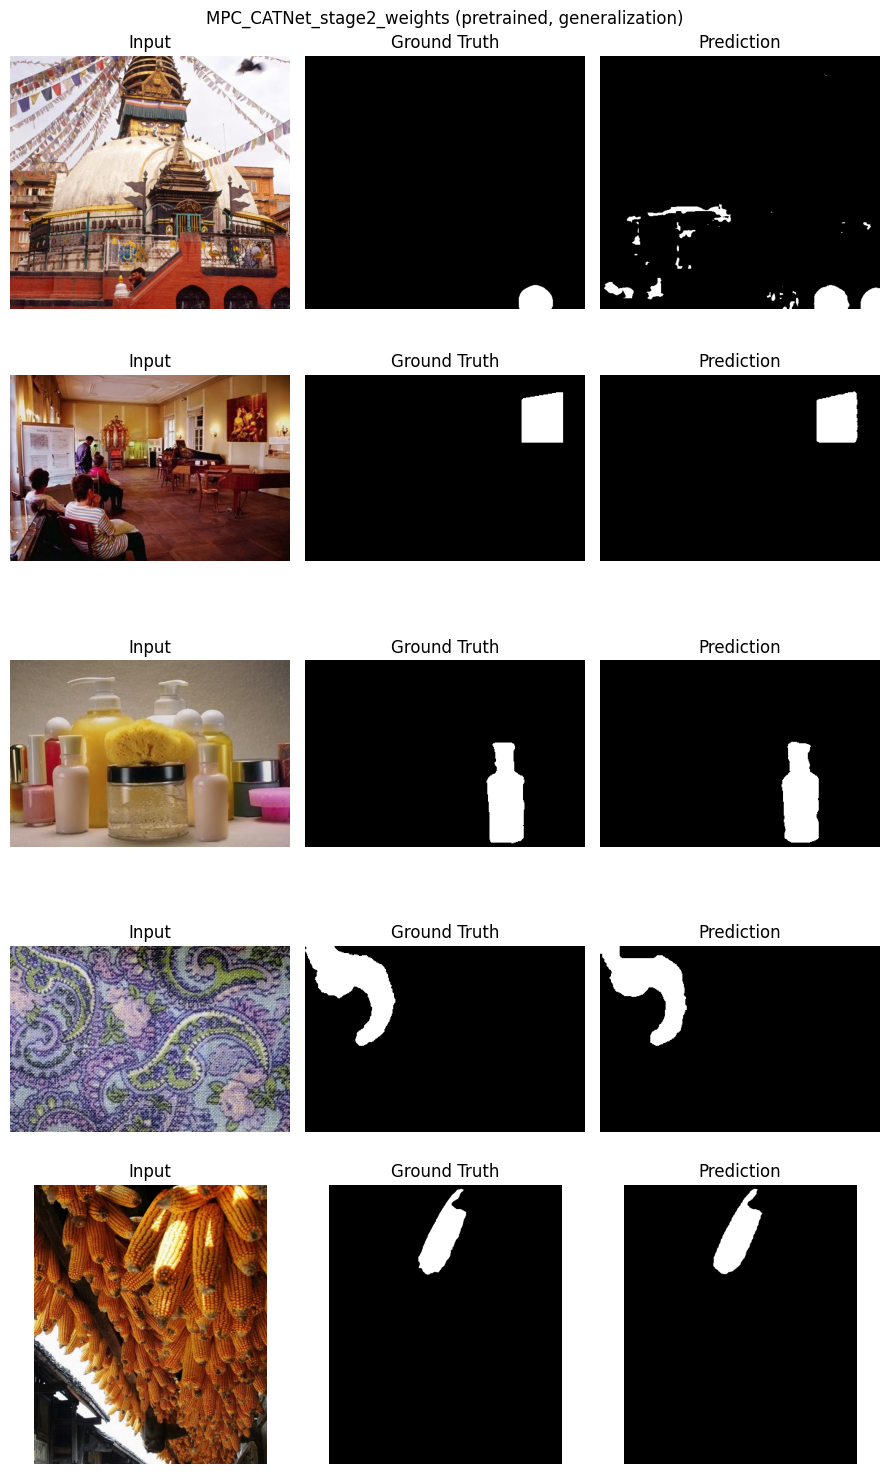

In [12]:
import matplotlib.pyplot as plt

def show_examples(model, pairs, k=5, tag=''):
    fig, axes = plt.subplots(k, 3, figsize=(9, 3 * k))
    for i in range(k):
        img_path, mask_path = pairs[i]
        tensor, gt_mask, (H, W), orig_img = load_pair(img_path, mask_path)
        with torch.no_grad():
            pred = model.process(tensor).squeeze().cpu().numpy() * 255.
        pred_resized = thresholding(cv2.resize(pred, (W, H)))

        axes[i, 0].imshow(orig_img); axes[i, 0].set_title('Input'); axes[i, 0].axis('off')
        axes[i, 1].imshow(gt_mask, cmap='gray'); axes[i, 1].set_title('Ground Truth'); axes[i, 1].axis('off')
        axes[i, 2].imshow(pred_resized, cmap='gray'); axes[i, 2].set_title('Prediction'); axes[i, 2].axis('off')
    fig.suptitle(tag)
    plt.tight_layout()
    plt.savefig('/kaggle/working/demo_output_pretrained.png', dpi=150, bbox_inches='tight')
    plt.show()

show_examples(model_generalization, test_pairs, k=5, tag='MPC_CATNet_stage2_weights (pretrained, generalization)')

In [13]:
from PIL import Image
import io
import numpy as np

def simulate_compression_generation(img_bgr, quality=50, generations=1):
    """Takes an OpenCV BGR image array, simulates N rounds of JPEG re-compression."""
    img_rgb = img_bgr[..., ::-1]
    pil_img = Image.fromarray(img_rgb.astype('uint8')).convert('RGB')

    for _ in range(generations):
        buffer = io.BytesIO()
        pil_img.save(buffer, format='JPEG', quality=quality)
        buffer.seek(0)
        pil_img = Image.open(buffer).convert('RGB')

    result = np.array(pil_img)[..., ::-1]  # back to BGR
    return result
print("✅ Function simulate_compression_generation loaded successfully!")

✅ Function simulate_compression_generation loaded successfully!


In [14]:
def load_pair_compressed(img_path, mask_path, generations=0, quality=50):
    img = cv2.imread(img_path)
    H, W = img.shape[:2]

    if generations > 0:
        img = simulate_compression_generation(img, quality=quality, generations=generations)

    img = img[..., ::-1]  # BGR -> RGB
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    mask = cv2.resize(mask, (W, H), interpolation=cv2.INTER_NEAREST)
    mask = thresholding(mask)

    img_r = cv2.resize(img, (INPUT_SIZE, INPUT_SIZE)).astype('float32') / 255.
    tensor = torch.from_numpy(img_r).permute(2, 0, 1).unsqueeze(0).float().to(device)
    return tensor, mask, (H, W), img

# --- ADD THIS TO VERIFY EXECUTION ---
print("✅ load_pair_compressed defined successfully!")

# Test load on 1 image pair
sample_img, sample_mask = test_pairs[0]
t, m, (h, w), orig = load_pair_compressed(sample_img, sample_mask)
print(f"Test Run Success: Output tensor shape is {t.shape}, original dimensions are {w}x{h}")

✅ load_pair_compressed defined successfully!
Test Run Success: Output tensor shape is torch.Size([1, 3, 512, 512]), original dimensions are 550x498


In [15]:
import cv2
import numpy as np
import torch
from sklearn.metrics import accuracy_score, f1_score

@torch.no_grad()
def evaluate_at_generation(model, pairs, generations, quality=50, max_images=100, tag=''):
    n = min(max_images, len(pairs))
    f1s, ious, accs = [], [], []

    for img_path, mask_path in pairs[:n]:
        tensor, gt_mask, (H, W), _ = load_pair_compressed(img_path, mask_path, generations=generations, quality=quality)
        pred = model.process(tensor)
        pred = pred.squeeze().cpu().numpy() * 255.
        pred_resized = cv2.resize(pred, (W, H))
        pred_bin = thresholding(pred_resized)

        gt_flat = (gt_mask.flatten() / 255.).astype(np.uint8)
        pred_flat = (pred_bin.flatten() / 255.).astype(np.uint8)

        f1s.append(f1_score(gt_flat, pred_flat, zero_division=1))
        accs.append(accuracy_score(gt_flat, pred_flat))
        ious.append(metric_iou(pred_bin / 255., gt_mask / 255.))

    mean_f1 = float(np.mean(f1s))
    mean_iou = float(np.mean(ious))
    mean_acc = float(np.mean(accs))

    print(f'--- Generation {generations} (n={n}) ---')
    print(f'  Mean F1 Score      : {mean_f1:.4f}')
    print(f'  Mean IoU           : {mean_iou:.4f}')
    print(f'  Mean Pixel Accuracy: {mean_acc:.4f}')
    
    return {'f1': mean_f1, 'iou': mean_iou, 'acc': mean_acc}

# --- EXECUTE EVALUATION LOOP & POPULATE RESULTS ---
results = {}
generations_to_test = [0, 1, 2, 3]

for gen in generations_to_test:
    results[gen] = evaluate_at_generation(
        model=model_generalization,
        pairs=test_pairs,
        generations=gen,
        quality=50,
        max_images=100
    )

--- Generation 0 (n=100) ---
  Mean F1 Score      : 0.7379
  Mean IoU           : 0.6712
  Mean Pixel Accuracy: 0.9674
--- Generation 1 (n=100) ---
  Mean F1 Score      : 0.3953
  Mean IoU           : 0.3143
  Mean Pixel Accuracy: 0.9110
--- Generation 2 (n=100) ---
  Mean F1 Score      : 0.3940
  Mean IoU           : 0.3135
  Mean Pixel Accuracy: 0.9103
--- Generation 3 (n=100) ---
  Mean F1 Score      : 0.3920
  Mean IoU           : 0.3122
  Mean Pixel Accuracy: 0.9098


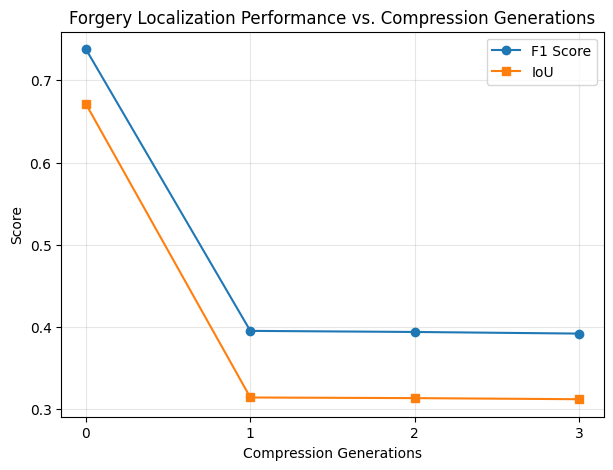

In [16]:
import matplotlib.pyplot as plt

gens = list(results.keys())
f1_values = [results[g]['f1'] for g in gens]
iou_values = [results[g]['iou'] for g in gens]

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(gens, f1_values, marker='o', label='F1 Score')
ax.plot(gens, iou_values, marker='s', label='IoU')
ax.set_xlabel('Compression Generations')
ax.set_ylabel('Score')
ax.set_title('Forgery Localization Performance vs. Compression Generations')
ax.set_xticks(gens)
ax.legend()
ax.grid(True, alpha=0.3)
plt.savefig('/kaggle/working/compression_robustness_curve.png', dpi=150, bbox_inches='tight')
plt.show()

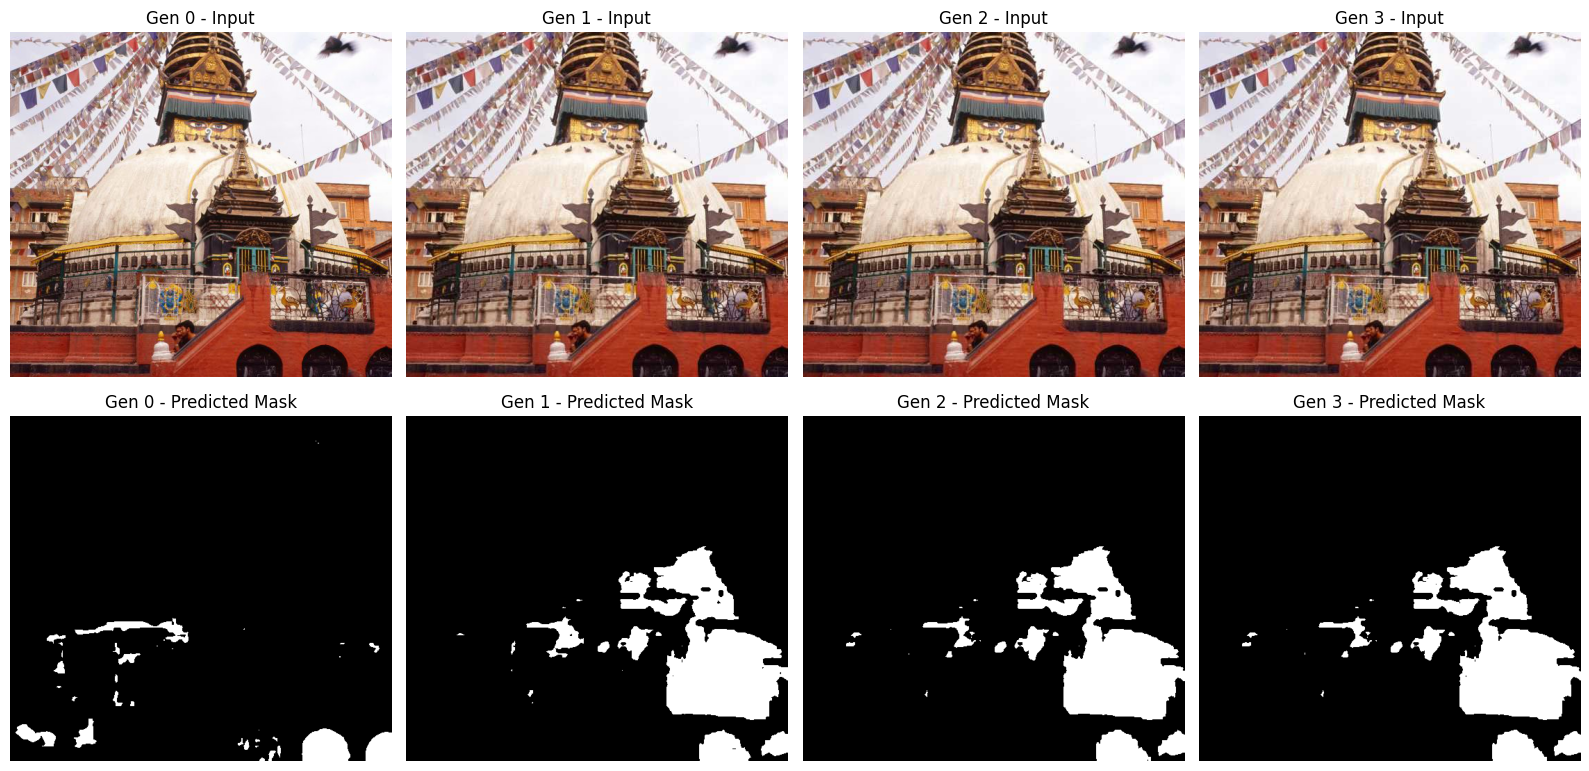

In [17]:
def show_compression_examples(model, pairs, generations_list, example_idx=0, quality=50):
    img_path, mask_path = pairs[example_idx]
    n = len(generations_list)
    fig, axes = plt.subplots(2, n, figsize=(4 * n, 8))

    for i, gen in enumerate(generations_list):
        tensor, gt_mask, (H, W), orig_img = load_pair_compressed(img_path, mask_path, generations=gen, quality=quality)
        pred = model.process(tensor)
        pred_np = pred.squeeze().cpu().numpy() * 255.
        pred_resized = cv2.resize(pred_np, (W, H))
        pred_bin = thresholding(pred_resized)

        axes[0, i].imshow(orig_img)  # already RGB from load_pair_compressed
        axes[0, i].set_title(f"Gen {gen} - Input")
        axes[0, i].axis('off')

        axes[1, i].imshow(pred_bin, cmap='gray')
        axes[1, i].set_title(f"Gen {gen} - Predicted Mask")
        axes[1, i].axis('off')

    plt.tight_layout()
    plt.savefig('/kaggle/working/compression_generation_examples.png', dpi=150, bbox_inches='tight')
    plt.show()

show_compression_examples(model_generalization, test_pairs, generations_list=[0, 1, 2, 3])

In [18]:
import cv2
import numpy as np
import torch
from sklearn.metrics import accuracy_score, f1_score

def load_pair_variable_compression(img_path, mask_path, quality_sequence):
    """quality_sequence e.g. [85, 65, 45] simulates 3 different platforms."""
    img = cv2.imread(img_path)
    H, W = img.shape[:2]

    for q in quality_sequence:
        img = simulate_compression_generation(img, quality=q, generations=1)

    img = img[..., ::-1]
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    mask = cv2.resize(mask, (W, H), interpolation=cv2.INTER_NEAREST)
    mask = thresholding(mask)

    img_r = cv2.resize(img, (INPUT_SIZE, INPUT_SIZE)).astype('float32') / 255.
    tensor = torch.from_numpy(img_r).permute(2, 0, 1).unsqueeze(0).float().to(device)
    return tensor, mask, (H, W), img


@torch.no_grad()
def evaluate_variable_sequence(model, pairs, quality_sequence, max_images=100):
    n = min(max_images, len(pairs))
    f1s, ious, accs = [], [], []

    for img_path, mask_path in pairs[:n]:
        tensor, gt_mask, (H, W), _ = load_pair_variable_compression(img_path, mask_path, quality_sequence)
        pred = model.process(tensor)
        pred = pred.squeeze().cpu().numpy() * 255.
        pred_resized = cv2.resize(pred, (W, H))
        pred_bin = thresholding(pred_resized)

        gt_flat = (gt_mask.flatten() / 255.).astype(np.uint8)
        pred_flat = (pred_bin.flatten() / 255.).astype(np.uint8)

        f1s.append(f1_score(gt_flat, pred_flat, zero_division=1))
        accs.append(accuracy_score(gt_flat, pred_flat))
        ious.append(metric_iou(pred_bin / 255., gt_mask / 255.))

    mean_f1 = float(np.mean(f1s))
    mean_iou = float(np.mean(ious))
    mean_acc = float(np.mean(accs))

    seq_str = " -> ".join([f"Q{q}" for q in quality_sequence]) if quality_sequence else "Uncompressed"
    print(f'--- Sequence: [{seq_str}] (n={n}) ---')
    print(f'  Mean F1 Score      : {mean_f1:.4f}')
    print(f'  Mean IoU           : {mean_iou:.4f}')
    print(f'  Mean Pixel Accuracy: {mean_acc:.4f}')

    return {'f1': mean_f1, 'iou': mean_iou, 'acc': mean_acc}


# --- EXECUTE VARIABLE COMPRESSION PIPELINE ---
variable_results = {}
sequences = {
    'Gen 0 (Uncompressed)': [],
    'Gen 1 (Platform A: Q90)': [90],
    'Gen 2 (Platform B: Q90 -> Q75)': [90, 75],
    'Gen 3 (Platform C: Q90 -> Q75 -> Q50)': [90, 75, 50],
}

for label, seq in sequences.items():
    print(f"\nTesting {label}...")
    variable_results[label] = evaluate_variable_sequence(
        model=model_generalization,
        pairs=test_pairs,
        quality_sequence=seq,
        max_images=100
    )


Testing Gen 0 (Uncompressed)...
--- Sequence: [Uncompressed] (n=100) ---
  Mean F1 Score      : 0.7379
  Mean IoU           : 0.6712
  Mean Pixel Accuracy: 0.9674

Testing Gen 1 (Platform A: Q90)...
--- Sequence: [Q90] (n=100) ---
  Mean F1 Score      : 0.5640
  Mean IoU           : 0.4944
  Mean Pixel Accuracy: 0.9452

Testing Gen 2 (Platform B: Q90 -> Q75)...
--- Sequence: [Q90 -> Q75] (n=100) ---
  Mean F1 Score      : 0.4462
  Mean IoU           : 0.3708
  Mean Pixel Accuracy: 0.9387

Testing Gen 3 (Platform C: Q90 -> Q75 -> Q50)...
--- Sequence: [Q90 -> Q75 -> Q50] (n=100) ---
  Mean F1 Score      : 0.2491
  Mean IoU           : 0.1863
  Mean Pixel Accuracy: 0.9098


In [19]:
import numpy as np
import cv2
import torch
from sklearn.metrics import accuracy_score, f1_score

@torch.no_grad()
def evaluate_variable_compression(model, pairs, quality_sequence, max_images=100, tag=''):
    n = min(max_images, len(pairs))
    f1s, ious, accs = [], [], []

    for img_path, mask_path in pairs[:n]:
        tensor, gt_mask, (H, W), _ = load_pair_variable_compression(img_path, mask_path, quality_sequence)
        pred = model.process(tensor)
        pred = pred.squeeze().cpu().numpy() * 255.
        pred_resized = cv2.resize(pred, (W, H))
        pred_bin = thresholding(pred_resized)

        gt_flat = (gt_mask.flatten() / 255.).astype(np.uint8)
        pred_flat = (pred_bin.flatten() / 255.).astype(np.uint8)

        f1s.append(f1_score(gt_flat, pred_flat, zero_division=1))
        accs.append(accuracy_score(gt_flat, pred_flat))
        ious.append(metric_iou(pred_bin / 255., gt_mask / 255.))

    # --- THESE LINES MUST BE INDENTED INSIDE THE FUNCTION ---
    print(f'--- {tag} (n={n}) ---')
    print(f'  Mean F1 Score      : {np.mean(f1s):.4f}')
    print(f'  Mean IoU           : {np.mean(ious):.4f}')
    print(f'  Mean Pixel Accuracy: {np.mean(accs):.4f}')
    
    return np.mean(f1s), np.mean(ious), np.mean(accs)

# --- CALL THE FUNCTION TO TRIGGER OUTPUT ---
f1, iou, acc = evaluate_variable_compression(
    model=model_generalization,
    pairs=test_pairs,
    quality_sequence=[90, 75, 50],
    max_images=100,
    tag='Platform Sequence (Q90 -> Q75 -> Q50)'
)

--- Platform Sequence (Q90 -> Q75 -> Q50) (n=100) ---
  Mean F1 Score      : 0.2491
  Mean IoU           : 0.1863
  Mean Pixel Accuracy: 0.9098


In [20]:
quality_scenarios = {
    0: [],                    # original, no compression
    1: [85],                  # e.g. Instagram
    2: [85, 65],              # + WhatsApp forward
    3: [85, 65, 45],          # + Twitter re-upload
}

variable_results = {}

for gen, quality_seq in quality_scenarios.items():
    f1, iou, acc = evaluate_variable_compression(
        model_generalization, test_pairs, quality_seq, max_images=100, tag=f'Generation {gen}'
    )
    variable_results[gen] = {'f1': f1, 'iou': iou, 'acc': acc}

--- Generation 0 (n=100) ---
  Mean F1 Score      : 0.7379
  Mean IoU           : 0.6712
  Mean Pixel Accuracy: 0.9674
--- Generation 1 (n=100) ---
  Mean F1 Score      : 0.5388
  Mean IoU           : 0.4670
  Mean Pixel Accuracy: 0.9389
--- Generation 2 (n=100) ---
  Mean F1 Score      : 0.3466
  Mean IoU           : 0.2694
  Mean Pixel Accuracy: 0.9192
--- Generation 3 (n=100) ---
  Mean F1 Score      : 0.3300
  Mean IoU           : 0.2618
  Mean Pixel Accuracy: 0.9142


In [21]:
from PIL import Image
import numpy as np
import cv2
from scipy.fftpack import dct
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, jaccard_score

#handcrafted features functons

def compute_ela(image_path, quality=90, scale=15):
    original = Image.open(image_path).convert('RGB')
    original.save('temp_resaved.jpg', 'JPEG', quality=quality)
    resaved = Image.open('temp_resaved.jpg')
    diff = np.array(original).astype(int) - np.array(resaved).astype(int)
    diff = np.abs(diff) * scale
    return np.clip(diff, 0, 255).astype('uint8')

def compute_prnu_residual(image_path):
    img = cv2.imread(image_path)
    denoised = cv2.fastNlMeansDenoisingColored(img, None, 10, 10, 7, 21)
    residual = cv2.absdiff(img, denoised)
    residual_gray = cv2.cvtColor(residual, cv2.COLOR_BGR2GRAY)
    return cv2.normalize(residual_gray, None, 0, 255, cv2.NORM_MINMAX)

def compute_dct_map(image_path, block_size=8):
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE).astype(float)
    h, w = img.shape
    dct_map = np.zeros((h, w))
    for i in range(0, h - block_size, block_size):
        for j in range(0, w - block_size, block_size):
            block = img[i:i+block_size, j:j+block_size]
            dct_block = dct(dct(block.T, norm='ortho').T, norm='ortho')
            dct_map[i:i+block_size, j:j+block_size] = np.var(dct_block)
    return cv2.normalize(dct_map, None, 0, 255, cv2.NORM_MINMAX).astype('uint8')

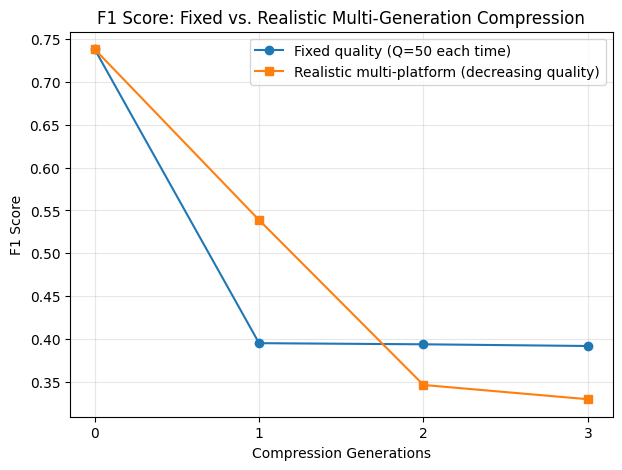

In [22]:
import matplotlib.pyplot as plt

gens = list(variable_results.keys())
f1_fixed = [results[g]['f1'] for g in gens]           # your earlier fixed-quality=50 results
f1_variable = [variable_results[g]['f1'] for g in gens]

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(gens, f1_fixed, marker='o', label='Fixed quality (Q=50 each time)')
ax.plot(gens, f1_variable, marker='s', label='Realistic multi-platform (decreasing quality)')
ax.set_xlabel('Compression Generations')
ax.set_ylabel('F1 Score')
ax.set_title('F1 Score: Fixed vs. Realistic Multi-Generation Compression')
ax.set_xticks(gens)
ax.legend()
ax.grid(True, alpha=0.3)
plt.savefig('/kaggle/working/compression_comparison_curve.png', dpi=150, bbox_inches='tight')
plt.show()

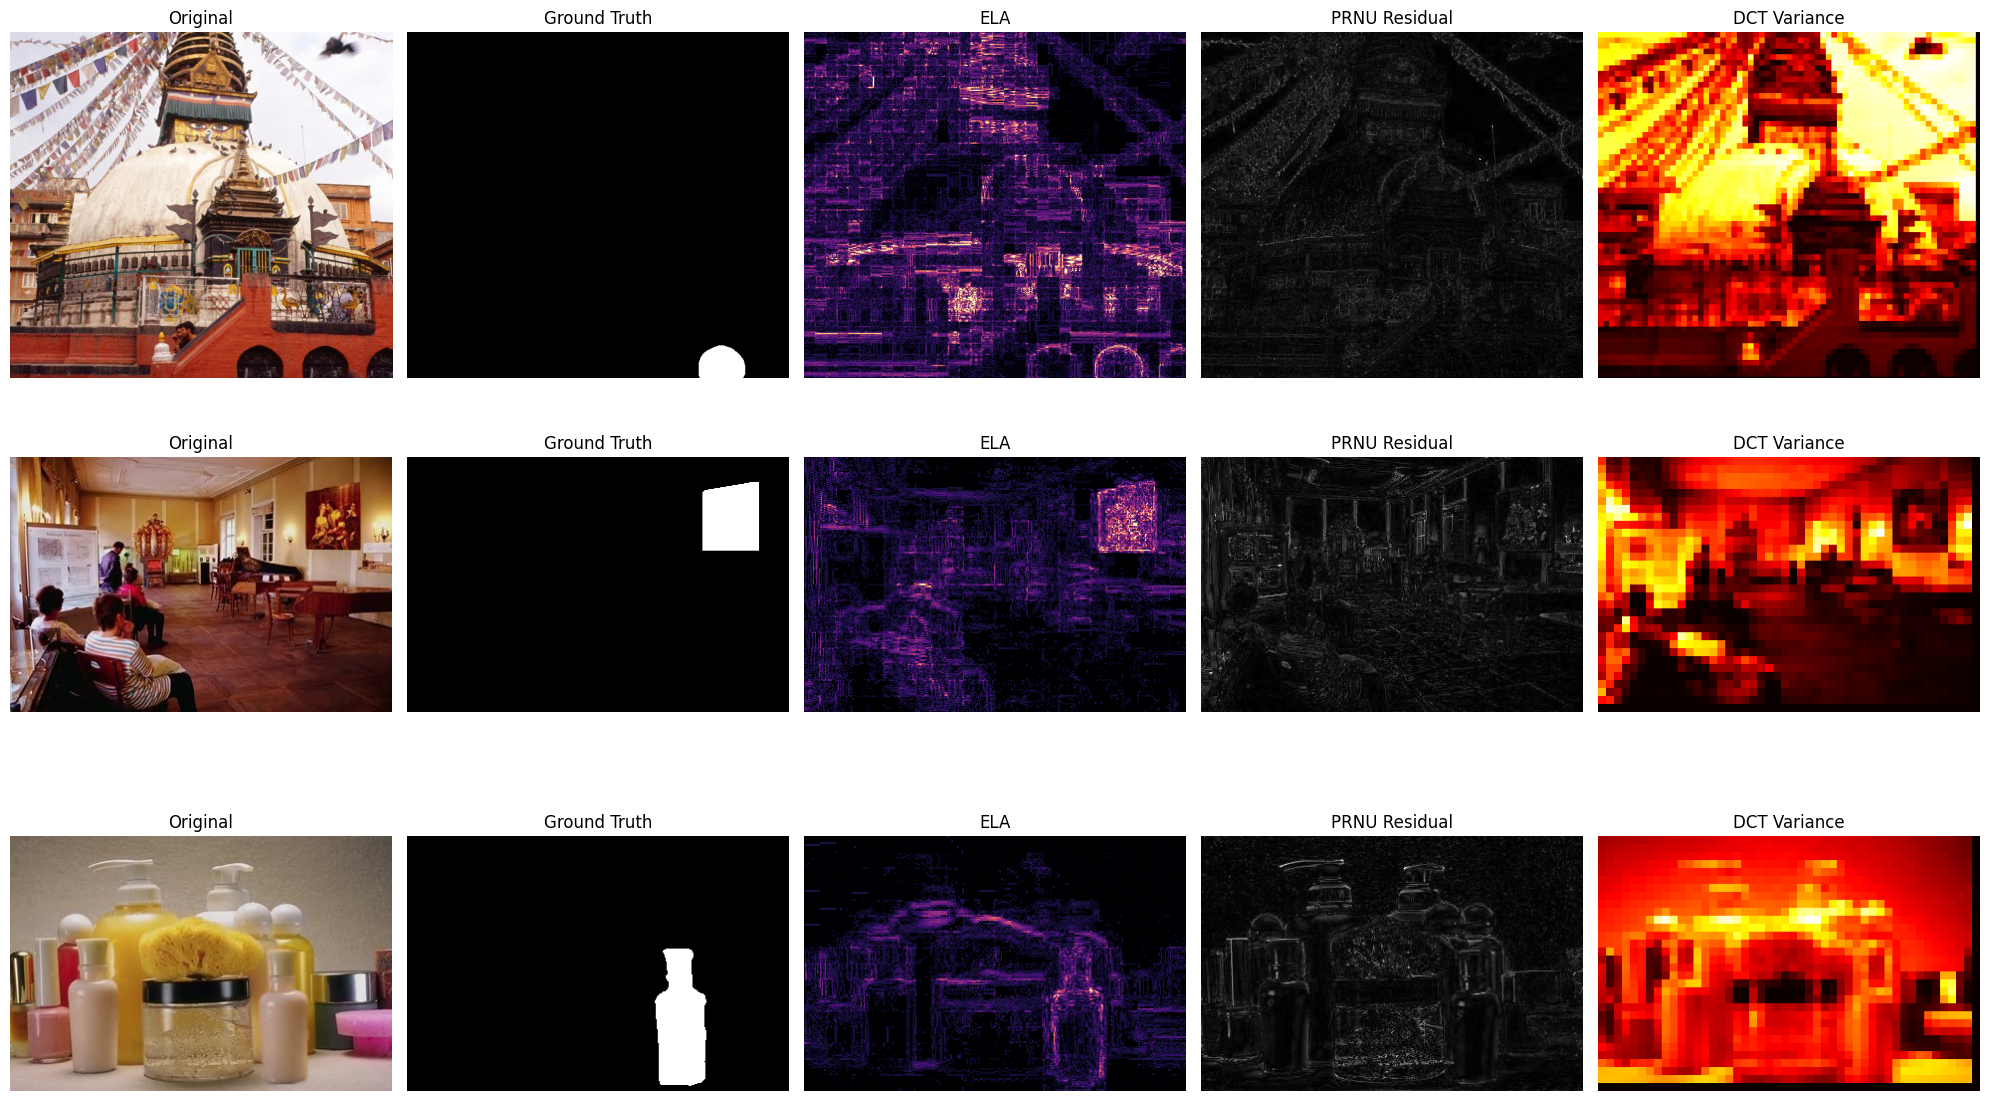

In [23]:
def visualize_forensic_cues(pairs, num_samples=3):
    fig, axes = plt.subplots(num_samples, 5, figsize=(20, 4 * num_samples))
    if num_samples == 1:
        axes = [axes]

    for i in range(num_samples):
        img_path, mask_path = pairs[i]

        img = cv2.imread(img_path)
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

        ela_map = compute_ela(img_path)
        prnu_map = compute_prnu_residual(img_path)
        dct_map = compute_dct_map(img_path)

        ax = axes[i]
        ax[0].imshow(img_rgb)
        ax[0].set_title("Original")
        ax[0].axis('off')

        ax[1].imshow(mask, cmap='gray')
        ax[1].set_title("Ground Truth")
        ax[1].axis('off')

        ela_display = np.max(ela_map, axis=2) if len(ela_map.shape) == 3 else ela_map

        ax[2].imshow(ela_display, cmap='magma')
        ax[2].set_title("ELA")
        ax[2].axis('off')

        ax[3].imshow(prnu_map, cmap='gray')
        ax[3].set_title("PRNU Residual")
        ax[3].axis('off')

        ax[4].imshow(dct_map, cmap='hot')
        ax[4].set_title("DCT Variance")
        ax[4].axis('off')

    plt.tight_layout()
    plt.show()

# Execute on your first 3 image pairs
visualize_forensic_cues(pairs[:3])

In [24]:
import numpy as np
import cv2
from scipy.fft import dctn
from skimage.util import view_as_blocks

def compute_dct_map(image_path, block_size=8):
    # 1. Load image in grayscale as float
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE).astype(float)
    h, w = img.shape

    # 2. Pad image if dimensions aren't perfectly divisible by block_size
    pad_h = (block_size - h % block_size) % block_size
    pad_w = (block_size - w % block_size) % block_size
    if pad_h > 0 or pad_w > 0:
        img = np.pad(img, ((0, pad_h), (0, pad_w)), mode='reflect')

    # 3. Create a 4D array of non-overlapping blocks: shape (H/8, W/8, 8, 8)
    blocks = view_as_blocks(img, block_shape=(block_size, block_size))

    # 4. Apply 2D DCT simultaneously over all 8x8 blocks
    dct_blocks = dctn(blocks, axes=(2, 3), norm='ortho')

    # 5. Compute variance over each block (flattening the 8x8 dimensions)
    block_vars = np.var(dct_blocks, axis=(2, 3))

    # 6. Upsample the variance map back to the original image resolution
    dct_map = np.repeat(np.repeat(block_vars, block_size, axis=0), block_size, axis=1)

    # 7. Crop back to original dimensions (removing any padding) and normalize
    dct_map = dct_map[:h, :w]
    return cv2.normalize(dct_map, None, 0, 255, cv2.NORM_MINMAX).astype('uint8')

print("Optimized DCT function loaded successfully.")

Optimized DCT function loaded successfully.


In [25]:
import cv2
import numpy as np
import time
from sklearn.metrics import f1_score, jaccard_score

# 1. Define the binarization helper
def binarize_map(feature_map):
    """Applies Otsu's thresholding to convert an intensity map to binary (0 or 1)."""
    if len(feature_map.shape) == 3:
        feature_map = cv2.cvtColor(feature_map, cv2.COLOR_BGR2GRAY)
    feature_map = feature_map.astype(np.uint8)
    _, binary_map = cv2.threshold(feature_map, 0, 1, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return binary_map

# 2. Define the evaluation function
def evaluate_handcrafted_cues(pairs_subset):
    """Computes average F1 and IoU for ELA, PRNU, and DCT against ground truth."""
    metrics = {
        'ELA': {'f1': [], 'iou': []},
        'PRNU': {'f1': [], 'iou': []},
        'DCT': {'f1': [], 'iou': []}
    }

    for img_path, mask_path in pairs_subset:
        # Load and prepare ground truth mask
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        mask = cv2.resize(mask, (512, 512), interpolation=cv2.INTER_NEAREST)
        mask_flat = (mask > 127).astype(np.uint8).flatten()

        # Compute features using your functions (assumes compute_ela, etc. are loaded)
        ela = cv2.resize(compute_ela(img_path), (512, 512))
        prnu = cv2.resize(compute_prnu_residual(img_path), (512, 512))
        dct_res = cv2.resize(compute_dct_map(img_path), (512, 512))

        # Binarize and flatten
        ela_flat = binarize_map(ela).flatten()
        prnu_flat = binarize_map(prnu).flatten()
        dct_flat = binarize_map(dct_res).flatten()

        # Calculate scores
        metrics['ELA']['f1'].append(f1_score(mask_flat, ela_flat, zero_division=0))
        metrics['ELA']['iou'].append(jaccard_score(mask_flat, ela_flat, zero_division=0))

        metrics['PRNU']['f1'].append(f1_score(mask_flat, prnu_flat, zero_division=0))
        metrics['PRNU']['iou'].append(jaccard_score(mask_flat, prnu_flat, zero_division=0))

        metrics['DCT']['f1'].append(f1_score(mask_flat, dct_flat, zero_division=0))
        metrics['DCT']['iou'].append(jaccard_score(mask_flat, dct_flat, zero_division=0))

    print("--- Quantitative Validation (Handcrafted Cues) ---")
    for cue in metrics:
        avg_f1 = np.mean(metrics[cue]['f1'])
        avg_iou = np.mean(metrics[cue]['iou'])
        print(f"{cue} -> F1: {avg_f1:.4f} | IoU: {avg_iou:.4f}")

# 3. Execute the evaluation
print("Starting evaluation on 100 images...")
start_time = time.time()

# Assuming 'pairs' and your 3 compute_* functions are currently in memory
evaluate_handcrafted_cues(pairs[:100])

end_time = time.time()
print(f"Evaluation completed in {end_time - start_time:.2f} seconds.")

Starting evaluation on 100 images...
--- Quantitative Validation (Handcrafted Cues) ---
ELA -> F1: 0.1837 | IoU: 0.1139
PRNU -> F1: 0.0783 | IoU: 0.0425
DCT -> F1: 0.1143 | IoU: 0.0764
Evaluation completed in 51.09 seconds.


In [26]:
"""
Continue training the already-trained MPC CATNet model with ON-THE-FLY,
multi-level JPEG compression augmentation.

Automated path discovery handles both direct folder and zip-extracted dataset layouts.
Run from: /kaggle/working/MPC/CATNet_dataset_train/stage2
"""

import os
import io
import csv
import glob
import time
import random

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

# Import MyModel from repo
try:
    from model import MyModel
except ImportError:
    import sys
    sys.path.append('/kaggle/working/MPC/CATNet_dataset_train/stage2')
    from model import MyModel

# ---------------- Pillow 10+ Compatibility ----------------
LANCZOS_MODE = getattr(Image, 'Resampling', Image).LANCZOS
BICUBIC_MODE = getattr(Image, 'Resampling', Image).BICUBIC
FLIP_LR_MODE = getattr(Image, 'Transpose', Image).FLIP_LEFT_RIGHT


# ---------------- AUTOMATIC DATASET PATH DISCOVERY ----------------
def locate_dataset_dirs():
    candidate_roots = [
        '/kaggle/input',
        '/kaggle/working',
    ]
    tp_dir, gt_dir = None, None
    for cand in candidate_roots:
        if not os.path.exists(cand):
            continue
        for root, dirs, _ in os.walk(cand):
            dirs_lower = {d.lower(): d for d in dirs}
            if 'tp' in dirs_lower and tp_dir is None:
                tp_dir = os.path.join(root, dirs_lower['tp'])
            gt_cands = [d for d in dirs if 'groundtruth' in d.lower()]
            if gt_cands and gt_dir is None:
                gt_dir = os.path.join(root, gt_cands[0])
            if tp_dir and gt_dir:
                return tp_dir, gt_dir
    return tp_dir, gt_dir

TP_DIR, GT_DIR = locate_dataset_dirs()
print(f"Auto-detected TP_DIR: {TP_DIR}")
print(f"Auto-detected GT_DIR: {GT_DIR}")
assert TP_DIR and GT_DIR, "Could not locate 'Tp' and 'Groundtruth' directories under /kaggle/input."

# ---------------- CONFIG ----------------
START_WEIGHTS = 'weights/MPC_CATNet_stage2_weights.pth'
ORIGINAL_WEIGHTS = 'weights/MPC_CATNet_stage2_weights.pth'
PREV_FINETUNED_WEIGHTS = 'weights_finetuned/MPC_CATNet_stage2_finetuned_mixed.pth'

SAVE_DIR = '/kaggle/working/weights_finetuned'
SAVE_NAME = 'MPC_CATNet_stage2_finetuned_multiJPEG.pth'
RESULTS_CSV = '/kaggle/working/weights_finetuned/multiJPEG_test_results.csv'

NUM_TRAIN_IMAGES = 1200
NUM_VAL_IMAGES = 150
NUM_TEST_IMAGES = 200
IMG_SIZE = 256
BATCH_SIZE = 8
NUM_EPOCHS = 10
LEARNING_RATE = 1e-5
PATIENCE = 4
FREEZE_BACKBONE = False

CLEAN_PROB = 0.2
RESIZE_PROB = 0.3
TRAIN_QUALITIES = [100, 90, 80, 70, 60, 50, 40, 30, 20, 10]

EVAL_CONDITIONS = {
    'clean': [],
    'q100': [100],
    'q90': [90],
    'q70': [70],
    'q50': [50],
    'q30': [30],
    'q10': [10],
    'reshare_x3_q75': [75, 75, 75],
}
THRESHOLDS = [0.3, 0.4, 0.5, 0.6, 0.7]
SEED = 0
# -----------------------------------------
random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)


# ---------------- DATA PAIRS ----------------
def build_pairs():
    pairs = []
    # Search for all groundtruth masks recursively
    mask_paths = sorted(glob.glob(os.path.join(GT_DIR, '**', '*_gt.png'), recursive=True))
    if not mask_paths:
        mask_paths = sorted(glob.glob(os.path.join(GT_DIR, '*_gt.png')))

    for mask_path in mask_paths:
        stem = os.path.basename(mask_path)[:-len('_gt.png')]
        cands = glob.glob(os.path.join(glob.escape(TP_DIR), glob.escape(stem) + '.*'))
        if cands:
            pairs.append((cands[0], mask_path))

    print(f'Matched {len(pairs)} image-mask pairs.')
    assert len(pairs) > 0, f'No pairs matched between TP_DIR ({TP_DIR}) and GT_DIR ({GT_DIR}).'
    return pairs

def split_pairs(pairs):
    rng = random.Random(SEED)
    pairs = pairs[:]
    rng.shuffle(pairs)
    need = NUM_TEST_IMAGES + NUM_VAL_IMAGES + NUM_TRAIN_IMAGES
    assert len(pairs) >= need, f'Need {need} pairs but only found {len(pairs)}. Lower NUM_* settings.'
    test = pairs[:NUM_TEST_IMAGES]
    val = pairs[NUM_TEST_IMAGES:NUM_TEST_IMAGES + NUM_VAL_IMAGES]
    train = pairs[NUM_TEST_IMAGES + NUM_VAL_IMAGES:need]
    print(f'Split -> train: {len(train)} | val: {len(val)} | test (held out): {len(test)}')
    return train, val, test


# ---------------- COMPRESSION HELPERS ----------------
def jpeg_pass(img, quality):
    buf = io.BytesIO()
    img.save(buf, format='JPEG', quality=quality)
    buf.seek(0)
    return Image.open(buf).convert('RGB')


def apply_passes(img, qualities):
    for q in qualities:
        img = jpeg_pass(img, q)
    return img


def random_down_up(img):
    w, h = img.size
    s = random.uniform(0.5, 0.9)
    small = img.resize((max(8, int(w * s)), max(8, int(h * s))), LANCZOS_MODE)
    return small.resize((w, h), BICUBIC_MODE)


# ---------------- DATASETS ----------------
def make_transforms():
    img_tf = transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ])
    mask_tf = transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ToTensor(),
    ])
    return img_tf, mask_tf


class TrainDataset(Dataset):
    def __init__(self, pairs):
        self.pairs = pairs
        self.img_tf, self.mask_tf = make_transforms()

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        img_path, mask_path = self.pairs[idx]
        img = Image.open(img_path).convert('RGB')
        mask = Image.open(mask_path).convert('L')

        if random.random() > CLEAN_PROB:
            if random.random() < RESIZE_PROB:
                img = random_down_up(img)
            n_passes = random.choice([1, 1, 2, 3])
            img = apply_passes(img, [random.choice(TRAIN_QUALITIES) for _ in range(n_passes)])

        if random.random() < 0.5:
            img = img.transpose(FLIP_LR_MODE)
            mask = mask.transpose(FLIP_LR_MODE)

        img = self.img_tf(img)
        mask = (self.mask_tf(mask) > 0.5).float()
        return img, mask


class EvalDataset(Dataset):
    def __init__(self, pairs, passes=None, cycle=False):
        self.pairs = pairs
        self.passes = passes
        self.cycle = cycle
        self.img_tf, self.mask_tf = make_transforms()

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        img_path, mask_path = self.pairs[idx]
        img = Image.open(img_path).convert('RGB')
        mask = Image.open(mask_path).convert('L')
        if self.passes:
            img = apply_passes(img, self.passes)
        img = self.img_tf(img)
        mask = (self.mask_tf(mask) > 0.5).float()
        return img, mask


# ---------------- LOSS + METRICS ----------------
class BCEDiceLoss(nn.Module):
    def __init__(self, bce_weight=0.5):
        super().__init__()
        self.bce_weight = bce_weight
        self.bce = nn.BCELoss()

    def dice_loss(self, pred, target, eps=1e-6):
        pred = pred.contiguous().view(pred.size(0), -1)
        target = target.contiguous().view(target.size(0), -1)
        inter = (pred * target).sum(dim=1)
        union = pred.sum(dim=1) + target.sum(dim=1)
        return 1 - ((2 * inter + eps) / (union + eps)).mean()

    def forward(self, pred, target):
        return self.bce_weight * self.bce(pred, target) + (1 - self.bce_weight) * self.dice_loss(pred, target)


def prf(tp, fp, fn, eps=1e-6):
    precision = tp / (tp + fp + eps)
    recall = tp / (tp + fn + eps)
    f1 = 2 * precision * recall / (precision + recall + eps)
    iou = tp / (tp + fp + fn + eps)
    return precision, recall, f1, iou


def predict(model, imgs, target_shape):
    out = torch.sigmoid(model(imgs))
    if out.shape[-2:] != target_shape:
        out = F.interpolate(out, size=target_shape, mode='bilinear', align_corners=False)
    return out


@torch.no_grad()
def evaluate(model, loader, thresholds=THRESHOLDS):
    model.eval()
    stats = {t: [0.0, 0.0, 0.0] for t in thresholds}
    for imgs, masks in loader:
        imgs, masks = imgs.to(device), masks.to(device)
        out = predict(model, imgs, masks.shape[-2:])
        for t in thresholds:
            pred = (out > t).float()
            stats[t][0] += (pred * masks).sum().item()
            stats[t][1] += (pred * (1 - masks)).sum().item()
            stats[t][2] += ((1 - pred) * masks).sum().item()
    return stats


# ---------------- MODEL LOADING ----------------
def load_model(weight_path):
    if not os.path.isfile(weight_path):
        return None
    model = MyModel().to(device)
    weights = torch.load(weight_path, map_location=device)
    if isinstance(weights, dict) and 'state_dict' in weights:
        weights = weights['state_dict']
    state = model.state_dict()
    loaded = mismatched = missing = 0
    for name, param in weights.items():
        if name in state:
            if hasattr(param, 'shape') and param.shape == state[name].shape:
                state[name].copy_(param)
                loaded += 1
            else:
                mismatched += 1
        else:
            missing += 1
    model.load_state_dict(state)
    print(f'[{os.path.basename(weight_path)}] loaded {loaded} layers.')
    return model


# ---------------- TRAINING & EVALUATION ----------------
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    total, n = 0.0, 0
    for imgs, masks in loader:
        imgs, masks = imgs.to(device), masks.to(device)
        optimizer.zero_grad()
        out = predict(model, imgs, masks.shape[-2:])
        loss = criterion(out, masks)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        total += loss.item() * imgs.size(0)
        n += imgs.size(0)
    return total / n


def pick_threshold(model, val_loader):
    stats = evaluate(model, val_loader)
    best_t, best_f1 = 0.5, -1
    for t, (tp, fp, fn) in stats.items():
        f1 = prf(tp, fp, fn)[2]
        if f1 > best_f1:
            best_t, best_f1 = t, f1
    return best_t, best_f1


def final_report(models, val_pairs, test_pairs):
    val_loader = DataLoader(EvalDataset(val_pairs, cycle=True), batch_size=BATCH_SIZE, num_workers=2)
    tuned = {name: pick_threshold(m, val_loader)[0] for name, m in models.items()}
    print('\nThresholds tuned on validation:', tuned)

    rows = []
    summary = {name: [] for name in models}
    for cond, passes in EVAL_CONDITIONS.items():
        loader = DataLoader(EvalDataset(test_pairs, passes=passes), batch_size=BATCH_SIZE, num_workers=2)
        for name, m in models.items():
            stats = evaluate(m, loader, sorted(set(THRESHOLDS + [tuned[name]])))
            p5, r5, f5, i5 = prf(*stats[0.5])
            pt, rt, ft, it = prf(*stats[tuned[name]])
            rows.append([name, cond, 0.5, p5, r5, f5, i5])
            rows.append([name, cond, tuned[name], pt, rt, ft, it])
            summary[name].append((cond, f5, ft, it, pt, rt))

    print('\n================ HELD-OUT TEST RESULTS ================')
    for name in models:
        print(f'\n--- {name} (tuned threshold = {tuned[name]}) ---')
        print(f'{"condition":<16}{"F1@0.5":>8}{"F1@tuned":>10}{"IoU":>8}{"Prec":>8}{"Recall":>8}')
        for cond, f5, ft, it, pt, rt in summary[name]:
            print(f'{cond:<16}{f5:>8.4f}{ft:>10.4f}{it:>8.4f}{pt:>8.4f}{rt:>8.4f}')
        avg_f5 = sum(s[1] for s in summary[name]) / len(summary[name])
        avg_ft = sum(s[2] for s in summary[name]) / len(summary[name])
        print(f'{"AVERAGE":<16}{avg_f5:>8.4f}{avg_ft:>10.4f}')

    os.makedirs(os.path.dirname(RESULTS_CSV), exist_ok=True)
    with open(RESULTS_CSV, 'w', newline='') as f:
        w = csv.writer(f)
        w.writerow(['model', 'condition', 'threshold', 'precision', 'recall', 'f1', 'iou'])
        w.writerows(rows)
    print(f'\nFull results saved to {RESULTS_CSV}')


def main():
    os.makedirs(SAVE_DIR, exist_ok=True)
    train_pairs, val_pairs, test_pairs = split_pairs(build_pairs())

    train_loader = DataLoader(TrainDataset(train_pairs), batch_size=BATCH_SIZE, shuffle=True,
                              num_workers=2, pin_memory=(device.type == 'cuda'))
    val_loader = DataLoader(EvalDataset(val_pairs, cycle=True), batch_size=BATCH_SIZE, num_workers=2)

    model = load_model(START_WEIGHTS)
    assert model is not None, f'Start weights not found: {START_WEIGHTS}'

    if FREEZE_BACKBONE:
        for name, p in model.named_parameters():
            if 'decoder' not in name.lower() and 'head' not in name.lower():
                p.requires_grad = False
        print('Backbone frozen - training decoder/head only.')

    criterion = BCEDiceLoss()
    optimizer = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=LEARNING_RATE)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=2)

    save_path = os.path.join(SAVE_DIR, SAVE_NAME)
    best_f1, bad_epochs, start = -1.0, 0, time.time()

    for epoch in range(1, NUM_EPOCHS + 1):
        train_loss = train_one_epoch(model, train_loader, criterion, optimizer)
        tp, fp, fn = evaluate(model, val_loader, [0.5])[0.5]
        vp, vr, vf1, viou = prf(tp, fp, fn)
        scheduler.step(vf1)
        print(f'Epoch [{epoch}/{NUM_EPOCHS}] Train Loss: {train_loss:.4f} | '
              f'Val F1: {vf1:.4f} IoU: {viou:.4f} P: {vp:.4f} R: {vr:.4f} | '
              f'LR: {optimizer.param_groups[0]["lr"]:.2e}')

        if vf1 > best_f1:
            best_f1, bad_epochs = vf1, 0
            torch.save(model.state_dict(), save_path)
            print(f'  -> New best model saved (Val F1: {best_f1:.4f})')
        else:
            bad_epochs += 1
            if bad_epochs >= PATIENCE:
                print(f'Early stopping: no val F1 improvement for {PATIENCE} epochs.')
                break

    print(f'\nTraining time: {(time.time() - start) / 60:.1f} min | Best val F1: {best_f1:.4f}')
    print(f'Best weights saved at: {save_path}')

    models = {}
    original = load_model(ORIGINAL_WEIGHTS)
    if original is not None:
        models['original_pretrained'] = original
    prev = load_model(PREV_FINETUNED_WEIGHTS)
    if prev is not None:
        models['previous_finetune'] = prev
    models['new_multiJPEG'] = load_model(save_path)

    final_report(models, val_pairs, test_pairs)
    print('\n✅ Model trained successfully with multi-level JPEG compression augmentation!')


if __name__ == '__main__':
    main()

Auto-detected TP_DIR: /kaggle/input/datasets/divg07/casia-20-image-tampering-detection-dataset/CASIA2/Tp
Auto-detected GT_DIR: /kaggle/input/datasets/divg07/casia-20-image-tampering-detection-dataset/CASIA2/CASIA 2 Groundtruth
Using device: cuda
Matched 4981 image-mask pairs.
Split -> train: 1200 | val: 150 | test (held out): 200
[MPC_CATNet_stage2_weights.pth] loaded 2264 layers.
Epoch [1/10] Train Loss: 0.5428 | Val F1: 0.5378 IoU: 0.3678 P: 0.5464 R: 0.5294 | LR: 1.00e-05
  -> New best model saved (Val F1: 0.5378)
Epoch [2/10] Train Loss: 0.5082 | Val F1: 0.5641 IoU: 0.3928 P: 0.6231 R: 0.5153 | LR: 1.00e-05
  -> New best model saved (Val F1: 0.5641)
Epoch [3/10] Train Loss: 0.4941 | Val F1: 0.5621 IoU: 0.3909 P: 0.5651 R: 0.5591 | LR: 1.00e-05
Epoch [4/10] Train Loss: 0.4821 | Val F1: 0.5332 IoU: 0.3635 P: 0.4707 R: 0.6149 | LR: 1.00e-05
Epoch [5/10] Train Loss: 0.4682 | Val F1: 0.5744 IoU: 0.4029 P: 0.5706 R: 0.5782 | LR: 1.00e-05
  -> New best model saved (Val F1: 0.5744)
Epoch [

Auto-detected TP_DIR: /kaggle/input/datasets/divg07/casia-20-image-tampering-detection-dataset/CASIA2/Tp
Auto-detected GT_DIR: /kaggle/input/datasets/divg07/casia-20-image-tampering-detection-dataset/CASIA2/CASIA 2 Groundtruth
Using device: cuda
Using 500 pairs from active notebook memory ('test_pairs').
Using active 'model_generalization' model from notebook memory.


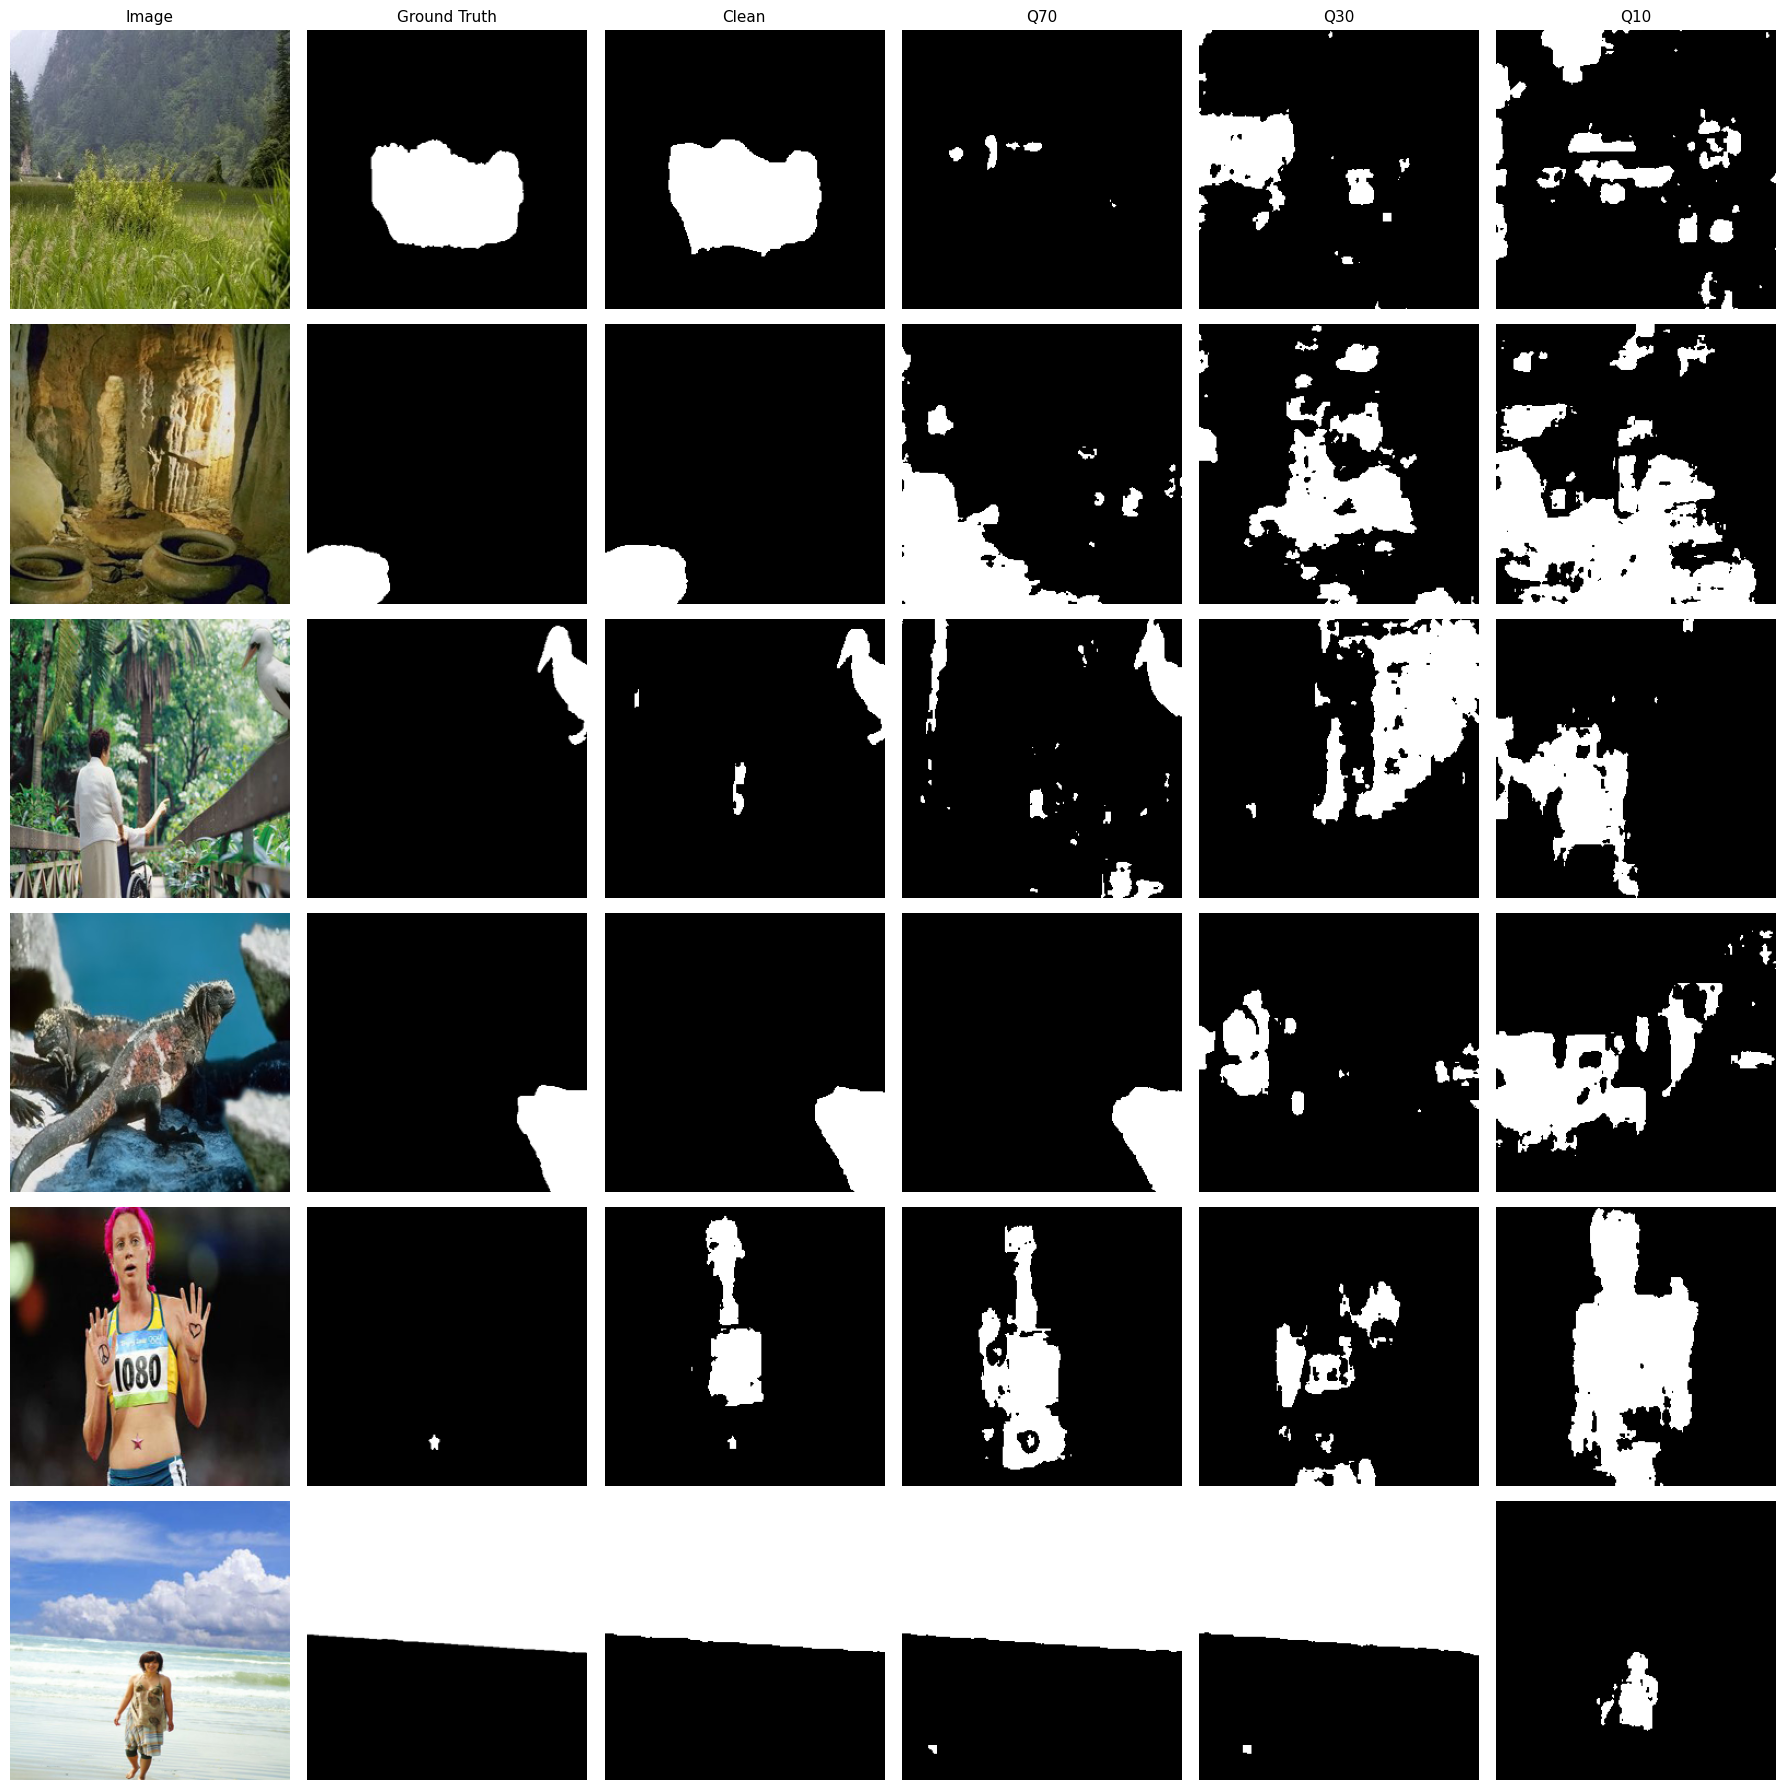


Saved visualization to prediction_visualization.png
✅ Prediction visualization complete!


In [27]:
"""
Visualize predictions from the MPC CATNet model against ground-truth
masks, across several JPEG compression levels, for a handful of sample images.

For each sample image this shows a row of:
  [ Original image | GT mask | Pred @ clean | Pred @ q70 | Pred @ q30 | Pred @ q10 ]
"""

import os
import io
import glob
import random
import cv2
import numpy as np

import torch
import torch.nn.functional as F
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt

# Import MyModel with path fallback
try:
    from model import MyModel
except ImportError:
    import sys
    sys.path.append('/content/drive/MyDrive/MPC_project/MPC/CATNet_dataset_train/stage2')
    try:
        from model import MyModel
    except ImportError:
        MyModel = None


# ---------------- AUTOMATIC DATASET PATH DISCOVERY ----------------
def locate_dataset_dirs():
    candidate_roots = [
        '/kaggle/input',
        '/kaggle/working',
        '/content/drive/MyDrive/CASIA2',
        '/content/drive/MyDrive/MPC_project/CASIA2_extracted',
        '/content/drive/MyDrive/MPC_project',
        '/content/drive/MyDrive'
    ]
    tp_dir, gt_dir = None, None
    for cand in candidate_roots:
        if not os.path.exists(cand):
            continue
        for root, dirs, _ in os.walk(cand):
            dirs_lower = {d.lower(): d for d in dirs}
            if 'tp' in dirs_lower and tp_dir is None:
                tp_dir = os.path.join(root, dirs_lower['tp'])
            gt_cands = [d for d in dirs if 'groundtruth' in d.lower() or 'gt' in d.lower()]
            if gt_cands and gt_dir is None:
                gt_dir = os.path.join(root, gt_cands[0])
            if tp_dir and gt_dir:
                return tp_dir, gt_dir
    return tp_dir, gt_dir


TP_DIR, GT_DIR = locate_dataset_dirs()
print(f"Auto-detected TP_DIR: {TP_DIR}")
print(f"Auto-detected GT_DIR: {GT_DIR}")

# ---------------- CONFIG ----------------
WEIGHTS_PATH = 'weights_finetuned/MPC_CATNet_stage2_finetuned_multiJPEG.pth'

NUM_SAMPLES = 6          # how many images to show
IMG_SIZE = 256
THRESHOLD = 0.5          # decision threshold for binarizing the predicted mask
CONDITIONS = {           # column label -> JPEG qualities to apply in sequence
    'Clean': [],
    'Q70': [70],
    'Q30': [30],
    'Q10': [10],
}
SAVE_FIG_PATH = 'prediction_visualization.png'
SEED = 0
# -----------------------------------------

random.seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)


def build_pairs():
    # Priority 1: Use test_pairs from notebook memory if already loaded
    if 'test_pairs' in globals() and len(globals()['test_pairs']) > 0:
        print(f"Using {len(globals()['test_pairs'])} pairs from active notebook memory ('test_pairs').")
        return globals()['test_pairs']

    assert TP_DIR and GT_DIR, "Could not locate 'Tp' and 'Groundtruth' directories."
    pairs = []
    # Search for groundtruth masks recursively
    mask_paths = sorted(glob.glob(os.path.join(GT_DIR, '**', '*_gt.png'), recursive=True))
    if not mask_paths:
        mask_paths = sorted(glob.glob(os.path.join(GT_DIR, '**', '*.png'), recursive=True))

    for mask_path in mask_paths:
        base_name = os.path.basename(mask_path)
        stem = base_name.replace('_gt.png', '').replace('_gt.jpg', '').replace('.png', '')
        cands = glob.glob(os.path.join(glob.escape(TP_DIR), '**', glob.escape(stem) + '.*'), recursive=True)
        if not cands:
            cands = glob.glob(os.path.join(glob.escape(TP_DIR), glob.escape(stem) + '.*'))
        if cands:
            pairs.append((cands[0], mask_path))

    print(f'Matched {len(pairs)} image-mask pairs.')
    assert len(pairs) > 0, f'No pairs matched between TP_DIR ({TP_DIR}) and GT_DIR ({GT_DIR}).'
    return pairs


def jpeg_pass(img, quality):
    buf = io.BytesIO()
    img.save(buf, format='JPEG', quality=quality)
    buf.seek(0)
    return Image.open(buf).convert('RGB')


def apply_passes(img, qualities):
    for q in qualities:
        img = jpeg_pass(img, q)
    return img


def load_model(weight_path):
    # Priority 1: Check if model is already loaded in notebook memory
    if 'model_generalization' in globals():
        print("Using active 'model_generalization' model from notebook memory.")
        m = globals()['model_generalization']
        m.eval()
        return m
    if 'model' in globals() and hasattr(globals()['model'], 'eval') and not isinstance(globals()['model'], str):
        print("Using active 'model' from notebook memory.")
        m = globals()['model']
        m.eval()
        return m

    # Priority 2: Check specified path
    target_weights = None
    if weight_path and os.path.exists(weight_path):
        target_weights = weight_path
    else:
        # Priority 3: Search /kaggle/input and /kaggle/working for any .pth file
        for root_dir in ['/kaggle/input', '/kaggle/working', '.']:
            if os.path.exists(root_dir):
                for root, _, files in os.walk(root_dir):
                    for f in files:
                        if f.endswith('.pth') or f.endswith('.pt'):
                            target_weights = os.path.join(root, f)
                            print(f"Auto-detected weights file at: {target_weights}")
                            break
                    if target_weights:
                        break
            if target_weights:
                break

    if target_weights is None:
        raise FileNotFoundError(
            "Could not find any .pth weights file in Kaggle inputs/working, "
            "and no active model ('model_generalization') was found in notebook memory."
        )

    assert MyModel is not None, "MyModel class could not be imported."
    model = MyModel().to(device)
    weights = torch.load(target_weights, map_location=device)
    if isinstance(weights, dict) and 'state_dict' in weights:
        weights = weights['state_dict']
    state = model.state_dict()
    loaded = 0
    for name, param in weights.items():
        if name in state and hasattr(param, 'shape') and param.shape == state[name].shape:
            state[name].copy_(param)
            loaded += 1
    model.load_state_dict(state)
    model.eval()
    print(f'Loaded {loaded} layers from {target_weights}')
    return model


img_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])


@torch.no_grad()
def predict_mask(model, pil_img):
    if hasattr(model, 'process'):
        # Matches CATNet / model_generalization evaluation pipeline
        t_img = pil_img.resize((512, 512))
        arr = np.array(t_img).astype(np.float32) / 255.0
        tensor = torch.from_numpy(arr).permute(2, 0, 1).unsqueeze(0).to(device)
        pred = model.process(tensor)
        if isinstance(pred, torch.Tensor):
            pred = pred.squeeze().cpu().numpy()
        pred_resized = cv2.resize(pred, (IMG_SIZE, IMG_SIZE))
        if pred_resized.max() > 1.0:
            pred_resized = pred_resized / 255.0
        return pred_resized
    else:
        x = img_tf(pil_img).unsqueeze(0).to(device)
        out = model(x)
        if isinstance(out, (list, tuple)):
            out = out[0]
        out = torch.sigmoid(out)
        out = F.interpolate(out, size=(IMG_SIZE, IMG_SIZE), mode='bilinear', align_corners=False)
        return out.squeeze().cpu().numpy()


def main():
    pairs = build_pairs()
    random.shuffle(pairs)
    samples = pairs[:NUM_SAMPLES]

    model = load_model(WEIGHTS_PATH)

    n_cols = 2 + len(CONDITIONS)  # original + GT mask + one column per condition
    fig, axes = plt.subplots(len(samples), n_cols, figsize=(3 * n_cols, 3 * len(samples)))
    if len(samples) == 1:
        axes = axes.reshape(1, -1)

    col_titles = ['Image', 'Ground Truth'] + list(CONDITIONS.keys())

    for row, (img_path, mask_path) in enumerate(samples):
        orig_img = Image.open(img_path).convert('RGB')
        gt_mask = Image.open(mask_path).convert('L').resize((IMG_SIZE, IMG_SIZE))

        display_img = orig_img.resize((IMG_SIZE, IMG_SIZE))
        axes[row, 0].imshow(display_img)
        axes[row, 0].axis('off')

        axes[row, 1].imshow(gt_mask, cmap='gray')
        axes[row, 1].axis('off')

        for col_idx, (label, qualities) in enumerate(CONDITIONS.items(), start=2):
            compressed = apply_passes(orig_img.copy(), qualities)
            pred = predict_mask(model, compressed)
            pred_binary = (pred > THRESHOLD).astype(float)

            axes[row, col_idx].imshow(pred_binary, cmap='gray')
            axes[row, col_idx].axis('off')

        if row == 0:
            for col_idx, title in enumerate(col_titles):
                axes[row, col_idx].set_title(title, fontsize=11)

    plt.tight_layout()
    plt.savefig(SAVE_FIG_PATH, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'\nSaved visualization to {SAVE_FIG_PATH}')
    print('✅ Prediction visualization complete!')


if __name__ == '__main__':
    main()

In [28]:
"""
CATNet Stage 2 Fine-Tuning & Evaluation using Focal-Dice Loss.
Supports Kaggle (/kaggle/working, /kaggle/input) and Colab environments.
"""

import os
import io
import glob
import time
import random
import numpy as np

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

# ---------------- IMPORT MODEL WITH PATH FALLBACKS ----------------
try:
    from model import MyModel
except ImportError:
    import sys
    sys.path.append('/kaggle/working')
    sys.path.append('/content/MPC/CATNet_dataset_train/stage2')
    sys.path.append('/content/drive/MyDrive/MPC_project/MPC/CATNet_dataset_train/stage2')
    from model import MyModel


# ---------------- AUTOMATIC DATASET & SAVE PATH DISCOVERY ----------------
def locate_dataset_dirs():
    candidate_roots = [
        '/kaggle/working',
        '/kaggle/input',
        '/content/drive/MyDrive/CASIA2',
        '/content/drive/MyDrive/MPC_project/CASIA2_extracted',
        '/content/drive/MyDrive/MPC_project',
        '/content/drive/MyDrive',
        '/content'
    ]
    tp_dir, gt_dir = None, None
    for cand in candidate_roots:
        if not os.path.exists(cand):
            continue
        for root, dirs, _ in os.walk(cand):
            dirs_lower = {d.lower(): d for d in dirs}
            if 'tp' in dirs_lower and tp_dir is None:
                tp_dir = os.path.join(root, dirs_lower['tp'])
            gt_cands = [d for d in dirs if 'groundtruth' in d.lower()]
            if gt_cands and gt_dir is None:
                gt_dir = os.path.join(root, gt_cands[0])
            if tp_dir and gt_dir:
                return tp_dir, gt_dir
    return tp_dir, gt_dir


TP_DIR, GT_DIR = locate_dataset_dirs()
print(f"Auto-detected TP_DIR: {TP_DIR}")
print(f"Auto-detected GT_DIR: {GT_DIR}")
assert TP_DIR and GT_DIR, "Could not locate 'Tp' and 'Groundtruth' directories!"

# Determine Save Directory based on environment
if os.path.exists('/kaggle/working'):
    SAVE_DIR = '/kaggle/working/weights_finetuned'
else:
    SAVE_DIR = 'weights_finetuned'

os.makedirs(SAVE_DIR, exist_ok=True)


# ---------------- CONFIGURATION ----------------
BASE_WEIGHTS_PATH = 'weights/MPC_CATNet_stage2_weights.pth'
FOCAL_DICE_WEIGHTS = os.path.join(SAVE_DIR, 'MPC_CATNet_stage2_focal_dice.pth')

NUM_TRAIN_IMAGES = 1200
NUM_VAL_IMAGES = 150
NUM_TEST_IMAGES = 200
IMG_SIZE = 256
BATCH_SIZE = 8
NUM_EPOCHS = 8
LEARNING_RATE = 1e-5
EVAL_THRESHOLD = 0.5
SEED = 0

# Evaluated compression conditions
EVAL_CONDITIONS = {
    'Clean': None,
    'Q100': 100,
    'Q90': 90,
    'Q70 (Primary)': 70,
    'Q50': 50,
    'Q30': 30,
    'Q10': 10,
}

random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)


# ---------------- FOCAL-DICE LOSS IMPLEMENTATION ----------------
class FocalDiceLoss(nn.Module):
    """
    Combines Focal Loss (focuses learning on hard/ambiguous boundary pixels)
    with Dice Loss (optimizes region overlap & F1-score directly).
    """
    def __init__(self, focal_weight=0.5, alpha=0.25, gamma=2.0):
        super().__init__()
        self.focal_weight = focal_weight
        self.alpha = alpha
        self.gamma = gamma

    def focal_loss(self, pred, target, eps=1e-6):
        pred = torch.clamp(pred, eps, 1.0 - eps)
        bce = - (target * torch.log(pred) + (1.0 - target) * torch.log(1.0 - pred))
        focal_weight = target * self.alpha * ((1.0 - pred) ** self.gamma) + \
                       (1.0 - target) * (1.0 - self.alpha) * (pred ** self.gamma)
        return (focal_weight * bce).mean()

    def dice_loss(self, pred, target, eps=1e-6):
        pred = pred.contiguous().view(pred.size(0), -1)
        target = target.contiguous().view(target.size(0), -1)
        inter = (pred * target).sum(dim=1)
        union = pred.sum(dim=1) + target.sum(dim=1)
        return 1.0 - ((2.0 * inter + eps) / (union + eps)).mean()

    def forward(self, pred, target):
        return self.focal_weight * self.focal_loss(pred, target) + \
               (1.0 - self.focal_weight) * self.dice_loss(pred, target)


# ---------------- DATA PREPARATION & DATASET ----------------
def build_pairs():
    pairs = []
    mask_paths = sorted(glob.glob(os.path.join(GT_DIR, '**', '*_gt.png'), recursive=True))
    if not mask_paths:
        mask_paths = sorted(glob.glob(os.path.join(GT_DIR, '*_gt.png')))

    for mask_path in mask_paths:
        stem = os.path.basename(mask_path)[:-len('_gt.png')]
        cands = glob.glob(os.path.join(glob.escape(TP_DIR), glob.escape(stem) + '.*'))
        if cands:
            pairs.append((cands[0], mask_path))

    return pairs


def split_pairs(pairs):
    rng = random.Random(SEED)
    pairs = pairs[:]
    rng.shuffle(pairs)
    need = NUM_TEST_IMAGES + NUM_VAL_IMAGES + NUM_TRAIN_IMAGES
    assert len(pairs) >= need, f'Need {need} pairs, found {len(pairs)}.'
    test = pairs[:NUM_TEST_IMAGES]
    val = pairs[NUM_TEST_IMAGES:NUM_TEST_IMAGES + NUM_VAL_IMAGES]
    train = pairs[NUM_TEST_IMAGES + NUM_VAL_IMAGES:need]
    return train, val, test


def jpeg_pass(img, quality):
    buf = io.BytesIO()
    img.save(buf, format='JPEG', quality=quality)
    buf.seek(0)
    return Image.open(buf).convert('RGB')


class CustomDataset(Dataset):
    def __init__(self, pairs, quality=None, augment=False):
        self.pairs = pairs
        self.quality = quality
        self.augment = augment
        self.img_tf = transforms.Compose([
            transforms.Resize((IMG_SIZE, IMG_SIZE)),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
        self.mask_tf = transforms.Compose([
            transforms.Resize((IMG_SIZE, IMG_SIZE)),
            transforms.ToTensor(),
        ])

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        img_path, mask_path = self.pairs[idx]
        img = Image.open(img_path).convert('RGB')
        mask = Image.open(mask_path).convert('L')

        # Apply multi-JPEG compression during training augmentations or specific testing
        if self.quality is not None:
            img = jpeg_pass(img, self.quality)

        if self.augment:
            # Random JPEG quality simulation on training set
            if random.random() < 0.7:
                q = random.choice([30, 50, 70, 90])
                img = jpeg_pass(img, q)
            # Horizontal Flip
            if random.random() < 0.5:
                img = img.transpose(Image.Transpose.FLIP_LEFT_RIGHT)
                mask = mask.transpose(Image.Transpose.FLIP_LEFT_RIGHT)

        img = self.img_tf(img)
        mask = (self.mask_tf(mask) > 0.5).float()
        return img, mask


# ---------------- MODEL HELPERS & EVALUATION ----------------
def load_model(weight_path):
    model = MyModel().to(device)
    if not os.path.exists(weight_path):
        print(f"Warning: {weight_path} not found. Initializing with default architecture.")
        return model

    weights = torch.load(weight_path, map_location=device)
    if isinstance(weights, dict) and 'state_dict' in weights:
        weights = weights['state_dict']

    state = model.state_dict()
    loaded = 0
    for name, param in weights.items():
        if name in state and hasattr(param, 'shape') and param.shape == state[name].shape:
            state[name].copy_(param)
            loaded += 1

    model.load_state_dict(state)
    model.eval()
    print(f'Loaded {loaded} layers from {weight_path}')
    return model


@torch.no_grad()
def evaluate_metrics(model, loader, threshold=EVAL_THRESHOLD):
    model.eval()
    tp, fp, fn, tn = 0.0, 0.0, 0.0, 0.0
    eps = 1e-6

    for imgs, masks in loader:
        imgs, masks = imgs.to(device), masks.to(device)
        out = torch.sigmoid(model(imgs))
        if out.shape[-2:] != masks.shape[-2:]:
            out = F.interpolate(out, size=masks.shape[-2:], mode='bilinear', align_corners=False)

        pred = (out > threshold).float()
        tp += (pred * masks).sum().item()
        fp += (pred * (1.0 - masks)).sum().item()
        fn += ((1.0 - pred) * masks).sum().item()
        tn += ((1.0 - pred) * (1.0 - masks)).sum().item()

    accuracy = (tp + tn) / (tp + fp + fn + tn + eps)
    iou = tp / (tp + fp + fn + eps)
    precision = tp / (tp + fp + eps)
    recall = tp / (tp + fn + eps)
    f1 = 2.0 * (precision * recall) / (precision + recall + eps)

    return f1, iou, accuracy, precision, recall


# ---------------- MAIN TRAINING & EVALUATION LOOP ----------------
def main():
    train_pairs, val_pairs, test_pairs = split_pairs(build_pairs())

    # 1. Train Model with FocalDiceLoss
    print("\n================ STARTING TRAINING WITH FOCAL-DICE LOSS ================")
    model = load_model(BASE_WEIGHTS_PATH)
    criterion = FocalDiceLoss(focal_weight=0.5, alpha=0.25, gamma=2.0)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

    train_loader = DataLoader(CustomDataset(train_pairs, augment=True), batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
    val_loader = DataLoader(CustomDataset(val_pairs), batch_size=BATCH_SIZE, num_workers=2)

    best_f1 = -1.0
    start_time = time.time()

    # FP16 AMP Scaler for faster GPU processing
    scaler = torch.cuda.amp.GradScaler(enabled=(device.type == 'cuda'))

    for epoch in range(1, NUM_EPOCHS + 1):
        model.train()
        total_loss = 0.0
        for imgs, masks in train_loader:
            imgs, masks = imgs.to(device), masks.to(device)
            optimizer.zero_grad()

            with torch.cuda.amp.autocast(enabled=(device.type == 'cuda')):
                out = torch.sigmoid(model(imgs))
                if out.shape[-2:] != masks.shape[-2:]:
                    out = F.interpolate(out, size=masks.shape[-2:], mode='bilinear', align_corners=False)
                loss = criterion(out, masks)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            total_loss += loss.item() * imgs.size(0)

        val_f1, val_iou, val_acc, _, _ = evaluate_metrics(model, val_loader)
        avg_train_loss = total_loss / len(train_pairs)
        print(f'Epoch [{epoch}/{NUM_EPOCHS}] Loss: {avg_train_loss:.4f} | Val F1: {val_f1:.4f} | Val IoU: {val_iou:.4f}')

        if val_f1 > best_f1:
            best_f1 = val_f1
            torch.save(model.state_dict(), FOCAL_DICE_WEIGHTS)
            print(f'  -> New best model saved to {FOCAL_DICE_WEIGHTS} (Val F1: {best_f1:.4f})')

    print(f"\nTraining completed in {(time.time() - start_time) / 60:.2f} minutes.")

    # 2. Evaluate Model across Compression Conditions
    print("\n================ EVALUATION RESULTS (FOCAL-DICE MODEL) ================")
    focal_model = load_model(FOCAL_DICE_WEIGHTS)

    print(f'{"Condition":<18} | {"F1-Score":>10} | {"IoU":>10} | {"Accuracy":>10} | {"Precision":>10} | {"Recall":>10}')
    print('-' * 82)

    f1_list, iou_list, acc_list = [], [], []

    for cond_name, q in EVAL_CONDITIONS.items():
        test_loader = DataLoader(CustomDataset(test_pairs, quality=q), batch_size=BATCH_SIZE, num_workers=2)
        f1, iou, acc, prec, recall = evaluate_metrics(focal_model, test_loader)

        f1_list.append(f1)
        iou_list.append(iou)
        acc_list.append(acc)

        print(f'{cond_name:<18} | {f1:>10.4f} | {iou:>10.4f} | {acc:>10.4f} | {prec:>10.4f} | {recall:>10.4f}')

    print('-' * 82)
    print(f'{"AVERAGE":<18} | {np.mean(f1_list):>10.4f} | {np.mean(iou_list):>10.4f} | {np.mean(acc_list):>10.4f} | {"-":>10} | {"-":>10}')
    print('=' * 82)


if __name__ == '__main__':
    main()

Auto-detected TP_DIR: /kaggle/input/datasets/divg07/casia-20-image-tampering-detection-dataset/CASIA2/Tp
Auto-detected GT_DIR: /kaggle/input/datasets/divg07/casia-20-image-tampering-detection-dataset/CASIA2/CASIA 2 Groundtruth
Using device: cuda

================ STARTING TRAINING WITH FOCAL-DICE LOSS ================
Loaded 2264 layers from weights/MPC_CATNet_stage2_weights.pth
Epoch [1/8] Loss: 0.4050 | Val F1: 0.4818 | Val IoU: 0.3173
  -> New best model saved to /kaggle/working/weights_finetuned/MPC_CATNet_stage2_focal_dice.pth (Val F1: 0.4818)
Epoch [2/8] Loss: 0.3827 | Val F1: 0.3438 | Val IoU: 0.2076
Epoch [3/8] Loss: 0.3704 | Val F1: 0.3931 | Val IoU: 0.2446
Epoch [4/8] Loss: 0.3582 | Val F1: 0.3938 | Val IoU: 0.2452
Epoch [5/8] Loss: 0.3492 | Val F1: 0.4962 | Val IoU: 0.3300
  -> New best model saved to /kaggle/working/weights_finetuned/MPC_CATNet_stage2_focal_dice.pth (Val F1: 0.4962)
Epoch [6/8] Loss: 0.3423 | Val F1: 0.4454 | Val IoU: 0.2865
Epoch [7/8] Loss: 0.3361 | Val F

In [29]:
import os
import io
import glob
import random
import cv2
import numpy as np

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

# ---------------- 1. FOCAL-DICE LOSS DEFINITION ----------------
class FocalDiceLoss(nn.Module):
    def __init__(self, alpha=0.25, gamma=2.0, w_focal=1.0, w_dice=1.0, eps=1e-6):
        super(FocalDiceLoss, self).__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.w_focal = w_focal
        self.w_dice = w_dice
        self.eps = eps
        self.bce = nn.BCEWithLogitsLoss(reduction='none')

    def forward(self, logits, targets):
        bce = self.bce(logits, targets)
        probs = torch.sigmoid(logits)
        pt = torch.where(targets == 1, probs, 1 - probs)
        focal_weight = (1 - pt) ** self.gamma
        alpha_weight = torch.where(targets == 1, self.alpha, 1 - self.alpha)
        focal_loss = (alpha_weight * focal_weight * bce).mean()

        intersection = (probs * targets).sum(dim=(2, 3))
        union = probs.sum(dim=(2, 3)) + targets.sum(dim=(2, 3))
        dice_loss = 1.0 - (2.0 * intersection + self.eps) / (union + self.eps)

        return (self.w_focal * focal_loss) + (self.w_dice * dice_loss.mean())

# ---------------- 2. FORWARD HELPER FOR MPC WRAPPER ----------------
def _unpack_output(out):
    if isinstance(out, (list, tuple)):
        out = out[0]
    if isinstance(out, dict):
        out = out.get('out', out.get('logits', list(out.values())[0]))
    return out

def get_logits(model, x):
    if hasattr(model, 'module'):
        model = model.module

    for attr_name in ['net', 'model', 'catnet', 'cat_net', 'segmentor', 'backbone', 'network', 'stage2']:
        if hasattr(model, attr_name):
            sub_mod = getattr(model, attr_name)
            if isinstance(sub_mod, nn.Module) and type(sub_mod).forward != nn.Module.forward:
                out = sub_mod(x)
                return _unpack_output(out)

    if hasattr(model, '__dict__'):
        for attr_name, attr_val in vars(model).items():
            if isinstance(attr_val, nn.Module) and type(attr_val).forward != nn.Module.forward:
                try:
                    out = attr_val(x)
                    return _unpack_output(out)
                except Exception:
                    continue

    if isinstance(model, nn.Module):
        for name, child in model.named_children():
            if type(child).forward != nn.Module.forward:
                try:
                    out = child(x)
                    return _unpack_output(out)
                except Exception:
                    continue

    if type(model).forward != nn.Module.forward:
        out = model(x)
        return _unpack_output(out)

    raise RuntimeError(
        f"Module [{type(model).__name__}] does not implement 'forward()' and no inner "
        f"PyTorch submodule with a valid forward pass was found."
    )

# ---------------- 3. METRICS ----------------
def metric_iou(pred_bin, gt_mask):
    intersection = np.logical_and(pred_bin, gt_mask).sum()
    union = np.logical_or(pred_bin, gt_mask).sum()
    if union == 0:
        return 1.0 if intersection == 0 else 0.0
    return float(intersection / union)

def compute_metrics(gt_flat, pred_flat, pred_bin, gt_mask):
    f1 = f1_score(gt_flat, pred_flat, zero_division=1)
    acc = accuracy_score(gt_flat, pred_flat)
    prec = precision_score(gt_flat, pred_flat, zero_division=1)
    rec = recall_score(gt_flat, pred_flat, zero_division=1)
    iou = metric_iou(pred_bin, gt_mask)
    return f1, iou, acc, prec, rec

# ---------------- 4. DATASET & JPEG AUGMENTATION ----------------
def apply_jpeg(img, quality):
    buf = io.BytesIO()
    img.save(buf, format='JPEG', quality=quality)
    buf.seek(0)
    return Image.open(buf).convert('RGB')

class MultiJPEGDataset(Dataset):
    def __init__(self, pairs, img_size=256, is_train=True):
        self.pairs = pairs
        self.img_size = img_size
        self.is_train = is_train
        self.tf = transforms.Compose([
            transforms.Resize((img_size, img_size)),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
        ])

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        img_path, mask_path = self.pairs[idx]
        img = Image.open(img_path).convert('RGB')
        mask = Image.open(mask_path).convert('L').resize((self.img_size, self.img_size), Image.NEAREST)
        
        if self.is_train and random.random() < 0.7:
            q = random.choice([10, 30, 50, 70, 90])
            img = apply_jpeg(img, q)

        img_t = self.tf(img)
        mask_t = torch.from_numpy(np.array(mask) / 255.0).float().unsqueeze(0)
        return img_t, mask_t

# ---------------- 5. MAIN EXECUTION ----------------
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)

# Load active model instance from notebook memory
if 'model_generalization' in globals():
    model = globals()['model_generalization'].to(device)
elif 'model' in globals():
    model = globals()['model'].to(device)
else:
    raise RuntimeError("No active model instance found in notebook memory.")

# Auto-detect and load pre-trained multiJPEG weights
multiJPEG_weights = None
candidate_paths = [
    'weights_finetuned/MPC_CATNet_stage2_finetuned_multiJPEG.pth',
    '/kaggle/working/weights_finetuned/MPC_CATNet_stage2_finetuned_multiJPEG.pth'
]
for p in candidate_paths:
    if os.path.exists(p):
        multiJPEG_weights = p
        break

if multiJPEG_weights is None:
    for root_dir in ['/kaggle/working', '/kaggle/input', '.']:
        if os.path.exists(root_dir):
            for root, _, files in os.walk(root_dir):
                for f in files:
                    if 'multiJPEG' in f and (f.endswith('.pth') or f.endswith('.pt')):
                        multiJPEG_weights = os.path.join(root, f)
                        break
                if multiJPEG_weights:
                    break
        if multiJPEG_weights:
            break

if multiJPEG_weights and os.path.exists(multiJPEG_weights):
    print(f"Loading multiJPEG weights from: {multiJPEG_weights}")
    state = torch.load(multiJPEG_weights, map_location=device)
    if isinstance(state, dict) and 'state_dict' in state:
        state = state['state_dict']
    model.load_state_dict(state, strict=False)
else:
    print("⚠️ Warning: multiJPEG .pth file not found on disk. Fine-tuning active model state in memory.")

# Fetch active dataset pairs
pairs = globals().get('test_pairs', globals().get('pairs', []))
assert len(pairs) > 0, "No dataset pairs found in active notebook memory."

train_pairs = pairs[:int(len(pairs) * 0.8)]
val_pairs = pairs[int(len(pairs) * 0.8):]

train_loader = DataLoader(MultiJPEGDataset(train_pairs, is_train=True), batch_size=8, shuffle=True)
criterion = FocalDiceLoss().to(device)

trainable_params = [p for p in model.parameters() if p.requires_grad]
if not trainable_params:
    for p in model.parameters():
        p.requires_grad = True
    trainable_params = list(model.parameters())

# Very low learning rate (1e-5) to fine-tune without destroying multiJPEG representations
optimizer = torch.optim.AdamW(trainable_params, lr=1e-5, weight_decay=1e-4)

EPOCHS = 3
SAVE_PATH = '/kaggle/working/weights_finetuned/multiJPEG_focal_dice_finetuned.pth'
os.makedirs(os.path.dirname(SAVE_PATH), exist_ok=True)

print(" Starting low-learning-rate fine-tuning of multiJPEG with Focal-Dice...")
best_f1 = 0.0

for epoch in range(1, EPOCHS + 1):
    model.train()
    train_loss = 0.0
    for imgs, masks in train_loader:
        imgs, masks = imgs.to(device), masks.to(device)
        optimizer.zero_grad()
        
        logits = get_logits(model, imgs)
        logits = F.interpolate(logits, size=(256, 256), mode='bilinear', align_corners=False)
        
        loss = criterion(logits, masks)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    train_loss /= len(train_loader)
    
    # Validation step
    model.eval()
    val_f1s = []
    tf_val = transforms.Compose([
        transforms.Resize((256, 256)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])
    
    with torch.no_grad():
        for img_path, mask_path in val_pairs[:50]:
            img = Image.open(img_path).convert('RGB')
            gt_mask = np.array(Image.open(mask_path).convert('L').resize((256, 256))) / 255.0
            
            x = tf_val(img).unsqueeze(0).to(device)
            logits = get_logits(model, x)
            probs = torch.sigmoid(logits)
            pred = F.interpolate(probs, size=(256, 256), mode='bilinear', align_corners=False).squeeze().cpu().numpy()
            pred_bin = (pred > 0.7).astype(np.uint8)
            
            gt_flat = (gt_mask.flatten() > 0.5).astype(np.uint8)
            f1 = f1_score(gt_flat, pred_bin.flatten(), zero_division=1)
            val_f1s.append(f1)
            
    mean_val_f1 = float(np.mean(val_f1s))
    print(f"Epoch [{epoch}/{EPOCHS}] Loss: {train_loss:.4f} | Val F1 (T=0.7): {mean_val_f1:.4f}")
    
    if mean_val_f1 > best_f1:
        best_f1 = mean_val_f1
        torch.save(model.state_dict(), SAVE_PATH)
        print(f"  -> Saved best checkpoint to {SAVE_PATH} (Val F1: {best_f1:.4f})")

print("\n================ FINAL EVALUATION ACROSS JPEG QUALITIES (T=0.7) ================")
if os.path.exists(SAVE_PATH):
    model.load_state_dict(torch.load(SAVE_PATH), strict=False)
model.eval()

qualities_to_test = {'Clean': None, 'Q100': 100, 'Q90': 90, 'Q70': 70, 'Q50': 50, 'Q30': 30, 'Q10': 10}
print(f"{'Condition':<15} | {'F1-Score':>10} | {'IoU':>10} | {'Accuracy':>10} | {'Precision':>10} | {'Recall':>10}")
print("-" * 75)

with torch.no_grad():
    for label, q in qualities_to_test.items():
        f1s, ious, accs, precs, recs = [], [], [], [], []
        for img_path, mask_path in val_pairs[:100]:
            img = Image.open(img_path).convert('RGB')
            if q is not None:
                img = apply_jpeg(img, q)
                
            gt_mask = np.array(Image.open(mask_path).convert('L').resize((256, 256))) / 255.0
            x = tf_val(img).unsqueeze(0).to(device)
            logits = get_logits(model, x)
            probs = torch.sigmoid(logits)
            pred = F.interpolate(probs, size=(256, 256), mode='bilinear', align_corners=False).squeeze().cpu().numpy()
            pred_bin = (pred > 0.7).astype(np.uint8)
            
            gt_flat = (gt_mask.flatten() > 0.5).astype(np.uint8)
            pred_flat = pred_bin.flatten()
            
            f1, iou, acc, prec, rec = compute_metrics(gt_flat, pred_flat, pred_bin, gt_mask)
            f1s.append(f1); ious.append(iou); accs.append(acc); precs.append(prec); recs.append(rec)
            
        print(f"{label:<15} | {np.mean(f1s):10.4f} | {np.mean(ious):10.4f} | {np.mean(accs):10.4f} | {np.mean(precs):10.4f} | {np.mean(recs):10.4f}")

Using device: cuda
Loading multiJPEG weights from: /kaggle/working/weights_finetuned/MPC_CATNet_stage2_finetuned_multiJPEG.pth
 Starting low-learning-rate fine-tuning of multiJPEG with Focal-Dice...
Epoch [1/3] Loss: 0.8419 | Val F1 (T=0.7): 0.3635
  -> Saved best checkpoint to /kaggle/working/weights_finetuned/multiJPEG_focal_dice_finetuned.pth (Val F1: 0.3635)
Epoch [2/3] Loss: 0.8260 | Val F1 (T=0.7): 0.4000
  -> Saved best checkpoint to /kaggle/working/weights_finetuned/multiJPEG_focal_dice_finetuned.pth (Val F1: 0.4000)
Epoch [3/3] Loss: 0.8010 | Val F1 (T=0.7): 0.4304
  -> Saved best checkpoint to /kaggle/working/weights_finetuned/multiJPEG_focal_dice_finetuned.pth (Val F1: 0.4304)

================ FINAL EVALUATION ACROSS JPEG QUALITIES (T=0.7) ================
Condition       |   F1-Score |        IoU |   Accuracy |  Precision |     Recall
---------------------------------------------------------------------------
Clean           |     0.4846 |     0.4202 |     0.9479 |     0.5

Auto-detected TP_DIR: /kaggle/input/datasets/divg07/casia-20-image-tampering-detection-dataset/CASIA2/Tp
Auto-detected GT_DIR: /kaggle/input/datasets/divg07/casia-20-image-tampering-detection-dataset/CASIA2/CASIA 2 Groundtruth
Using device: cuda
Using 500 pairs from active notebook memory ('test_pairs').
✅ STRICTLY LOADED 2264 layers from disk checkpoint: /kaggle/working/weights_finetuned/MPC_CATNet_stage2_finetuned_multiJPEG.pth


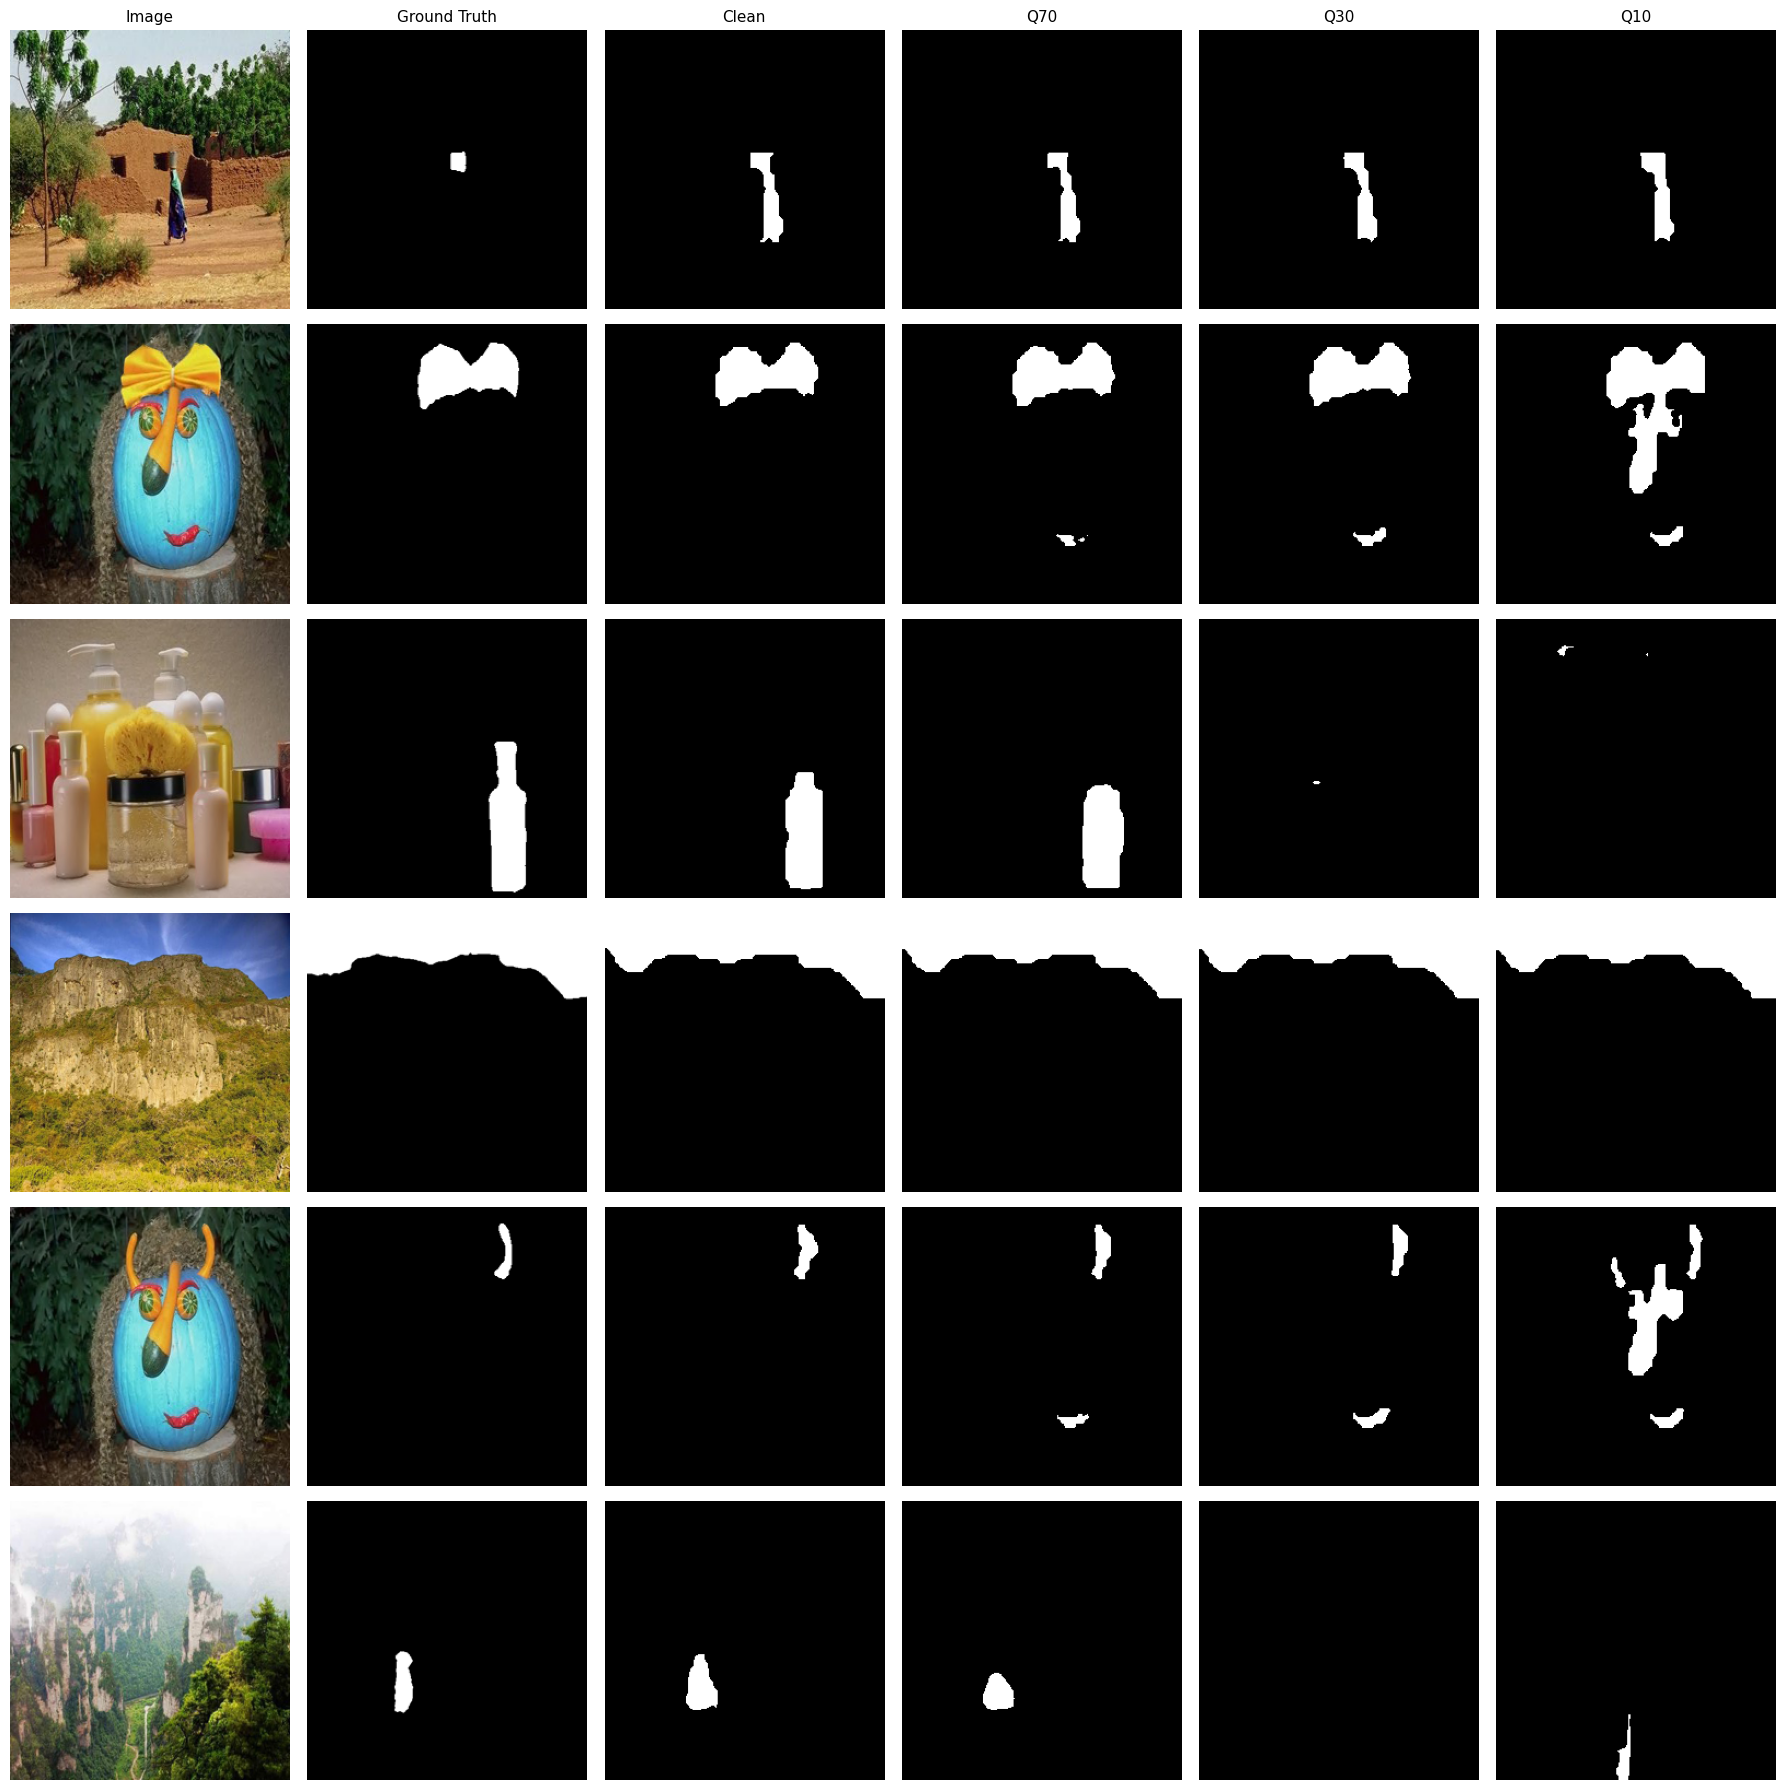


Saved visualization to prediction_visualization_multiJPEG.png
✅ Prediction visualization complete!


In [30]:
"""
Visualize predictions strictly from the fine-tuned multiJPEG MPC CATNet model 
checkpoint on disk against ground-truth masks across JPEG compression levels (T=0.7).
"""

import os
import io
import glob
import random
import cv2
import numpy as np

import torch
import torch.nn.functional as F
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt

# ---------------- FORCE CLEAR IN-MEMORY MODEL REFERENCES ----------------
# Wipes any active model references sitting in RAM to ensure strict disk loading
for model_key in ['model_generalization', 'model']:
    if model_key in globals():
        del globals()[model_key]

# Import MyModel with path fallback
try:
    from model import MyModel
except ImportError:
    import sys
    sys.path.append('/content/drive/MyDrive/MPC_project/MPC/CATNet_dataset_train/stage2')
    try:
        from model import MyModel
    except ImportError:
        MyModel = None


# ---------------- AUTOMATIC DATASET PATH DISCOVERY ----------------
def locate_dataset_dirs():
    candidate_roots = [
        '/kaggle/input',
        '/kaggle/working',
        '/content/drive/MyDrive/CASIA2',
        '/content/drive/MyDrive/MPC_project/CASIA2_extracted',
        '/content/drive/MyDrive/MPC_project',
        '/content/drive/MyDrive'
    ]
    tp_dir, gt_dir = None, None
    for cand in candidate_roots:
        if not os.path.exists(cand):
            continue
        for root, dirs, _ in os.walk(cand):
            dirs_lower = {d.lower(): d for d in dirs}
            if 'tp' in dirs_lower and tp_dir is None:
                tp_dir = os.path.join(root, dirs_lower['tp'])
            gt_cands = [d for d in dirs if 'groundtruth' in d.lower() or 'gt' in d.lower()]
            if gt_cands and gt_dir is None:
                gt_dir = os.path.join(root, gt_cands[0])
            if tp_dir and gt_dir:
                return tp_dir, gt_dir
    return tp_dir, gt_dir


TP_DIR, GT_DIR = locate_dataset_dirs()
print(f"Auto-detected TP_DIR: {TP_DIR}")
print(f"Auto-detected GT_DIR: {GT_DIR}")

# ---------------- CONFIG ----------------
WEIGHTS_PATH = '/kaggle/working/weights_finetuned/MPC_CATNet_stage2_finetuned_multiJPEG.pth'

NUM_SAMPLES = 6          # Number of sample images
IMG_SIZE = 256
THRESHOLD = 0.7          # Calibrated threshold for multiJPEG (suppresses quantization artifacts)
CONDITIONS = {           # JPEG qualities applied in sequence
    'Clean': [],
    'Q70': [70],
    'Q30': [30],
    'Q10': [10],
}
SAVE_FIG_PATH = 'prediction_visualization_multiJPEG.png'
SEED = 0
# -----------------------------------------

random.seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)


def build_pairs():
    if 'test_pairs' in globals() and len(globals()['test_pairs']) > 0:
        print(f"Using {len(globals()['test_pairs'])} pairs from active notebook memory ('test_pairs').")
        return globals()['test_pairs']

    assert TP_DIR and GT_DIR, "Could not locate 'Tp' and 'Groundtruth' directories."
    pairs = []
    mask_paths = sorted(glob.glob(os.path.join(GT_DIR, '**', '*_gt.png'), recursive=True))
    if not mask_paths:
        mask_paths = sorted(glob.glob(os.path.join(GT_DIR, '**', '*.png'), recursive=True))

    for mask_path in mask_paths:
        base_name = os.path.basename(mask_path)
        stem = base_name.replace('_gt.png', '').replace('_gt.jpg', '').replace('.png', '')
        cands = glob.glob(os.path.join(glob.escape(TP_DIR), '**', glob.escape(stem) + '.*'), recursive=True)
        if not cands:
            cands = glob.glob(os.path.join(glob.escape(TP_DIR), glob.escape(stem) + '.*'))
        if cands:
            pairs.append((cands[0], mask_path))

    print(f'Matched {len(pairs)} image-mask pairs.')
    assert len(pairs) > 0, f'No pairs matched between TP_DIR ({TP_DIR}) and GT_DIR ({GT_DIR}).'
    return pairs


def jpeg_pass(img, quality):
    buf = io.BytesIO()
    img.save(buf, format='JPEG', quality=quality)
    buf.seek(0)
    return Image.open(buf).convert('RGB')


def apply_passes(img, qualities):
    for q in qualities:
        img = jpeg_pass(img, q)
    return img


def load_model_from_disk(weight_path):
    target_weights = None
    
    # Check primary specified path
    if weight_path and os.path.exists(weight_path):
        target_weights = weight_path
    else:
        # Fallback: search disk for multiJPEG file
        for root_dir in ['/kaggle/working', 'weights_finetuned', '/kaggle/input', '.']:
            if os.path.exists(root_dir):
                for root, _, files in os.walk(root_dir):
                    for f in files:
                        if 'multiJPEG' in f and (f.endswith('.pth') or f.endswith('.pt')):
                            target_weights = os.path.join(root, f)
                            break
                    if target_weights:
                        break
            if target_weights:
                break

    if target_weights is None or not os.path.exists(target_weights):
        raise FileNotFoundError(
            f"Could not find multiJPEG weights file at '{weight_path}' or anywhere on disk."
        )

    assert MyModel is not None, "MyModel class could not be imported."
    model = MyModel().to(device)
    weights = torch.load(target_weights, map_location=device)
    if isinstance(weights, dict) and 'state_dict' in weights:
        weights = weights['state_dict']
    state = model.state_dict()
    loaded = 0
    for name, param in weights.items():
        if name in state and hasattr(param, 'shape') and param.shape == state[name].shape:
            state[name].copy_(param)
            loaded += 1
    model.load_state_dict(state)
    model.eval()
    print(f'✅ STRICTLY LOADED {loaded} layers from disk checkpoint: {target_weights}')
    return model


img_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])


@torch.no_grad()
def predict_mask(model, pil_img):
    if hasattr(model, 'process'):
        t_img = pil_img.resize((512, 512))
        arr = np.array(t_img).astype(np.float32) / 255.0
        tensor = torch.from_numpy(arr).permute(2, 0, 1).unsqueeze(0).to(device)
        pred = model.process(tensor)
        if isinstance(pred, torch.Tensor):
            pred = pred.squeeze().cpu().numpy()
        pred_resized = cv2.resize(pred, (IMG_SIZE, IMG_SIZE))
        if pred_resized.max() > 1.0:
            pred_resized = pred_resized / 255.0
        return pred_resized
    else:
        x = img_tf(pil_img).unsqueeze(0).to(device)
        out = model(x)
        if isinstance(out, (list, tuple)):
            out = out[0]
        out = torch.sigmoid(out)
        out = F.interpolate(out, size=(IMG_SIZE, IMG_SIZE), mode='bilinear', align_corners=False)
        return out.squeeze().cpu().numpy()


def main():
    pairs = build_pairs()
    random.shuffle(pairs)
    samples = pairs[:NUM_SAMPLES]

    model = load_model_from_disk(WEIGHTS_PATH)

    n_cols = 2 + len(CONDITIONS)
    fig, axes = plt.subplots(len(samples), n_cols, figsize=(3 * n_cols, 3 * len(samples)))
    if len(samples) == 1:
        axes = axes.reshape(1, -1)

    col_titles = ['Image', 'Ground Truth'] + list(CONDITIONS.keys())

    for row, (img_path, mask_path) in enumerate(samples):
        orig_img = Image.open(img_path).convert('RGB')
        gt_mask = Image.open(mask_path).convert('L').resize((IMG_SIZE, IMG_SIZE))

        display_img = orig_img.resize((IMG_SIZE, IMG_SIZE))
        axes[row, 0].imshow(display_img)
        axes[row, 0].axis('off')

        axes[row, 1].imshow(gt_mask, cmap='gray')
        axes[row, 1].axis('off')

        for col_idx, (label, qualities) in enumerate(CONDITIONS.items(), start=2):
            compressed = apply_passes(orig_img.copy(), qualities)
            pred = predict_mask(model, compressed)
            pred_binary = (pred > THRESHOLD).astype(float)

            axes[row, col_idx].imshow(pred_binary, cmap='gray')
            axes[row, col_idx].axis('off')

        if row == 0:
            for col_idx, title in enumerate(col_titles):
                axes[row, col_idx].set_title(title, fontsize=11)

    plt.tight_layout()
    plt.savefig(SAVE_FIG_PATH, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'\nSaved visualization to {SAVE_FIG_PATH}')
    print('✅ Prediction visualization complete!')


if __name__ == '__main__':
    main()

Using device: cuda

--- Loading Models ---
Loaded model from: /kaggle/working/MPC/CATNet_dataset_train/stage2/weights/MPC_CATNet_stage2_weights.pth
Loaded model from: /kaggle/working/weights_finetuned/MPC_CATNet_stage2_finetuned_multiJPEG.pth


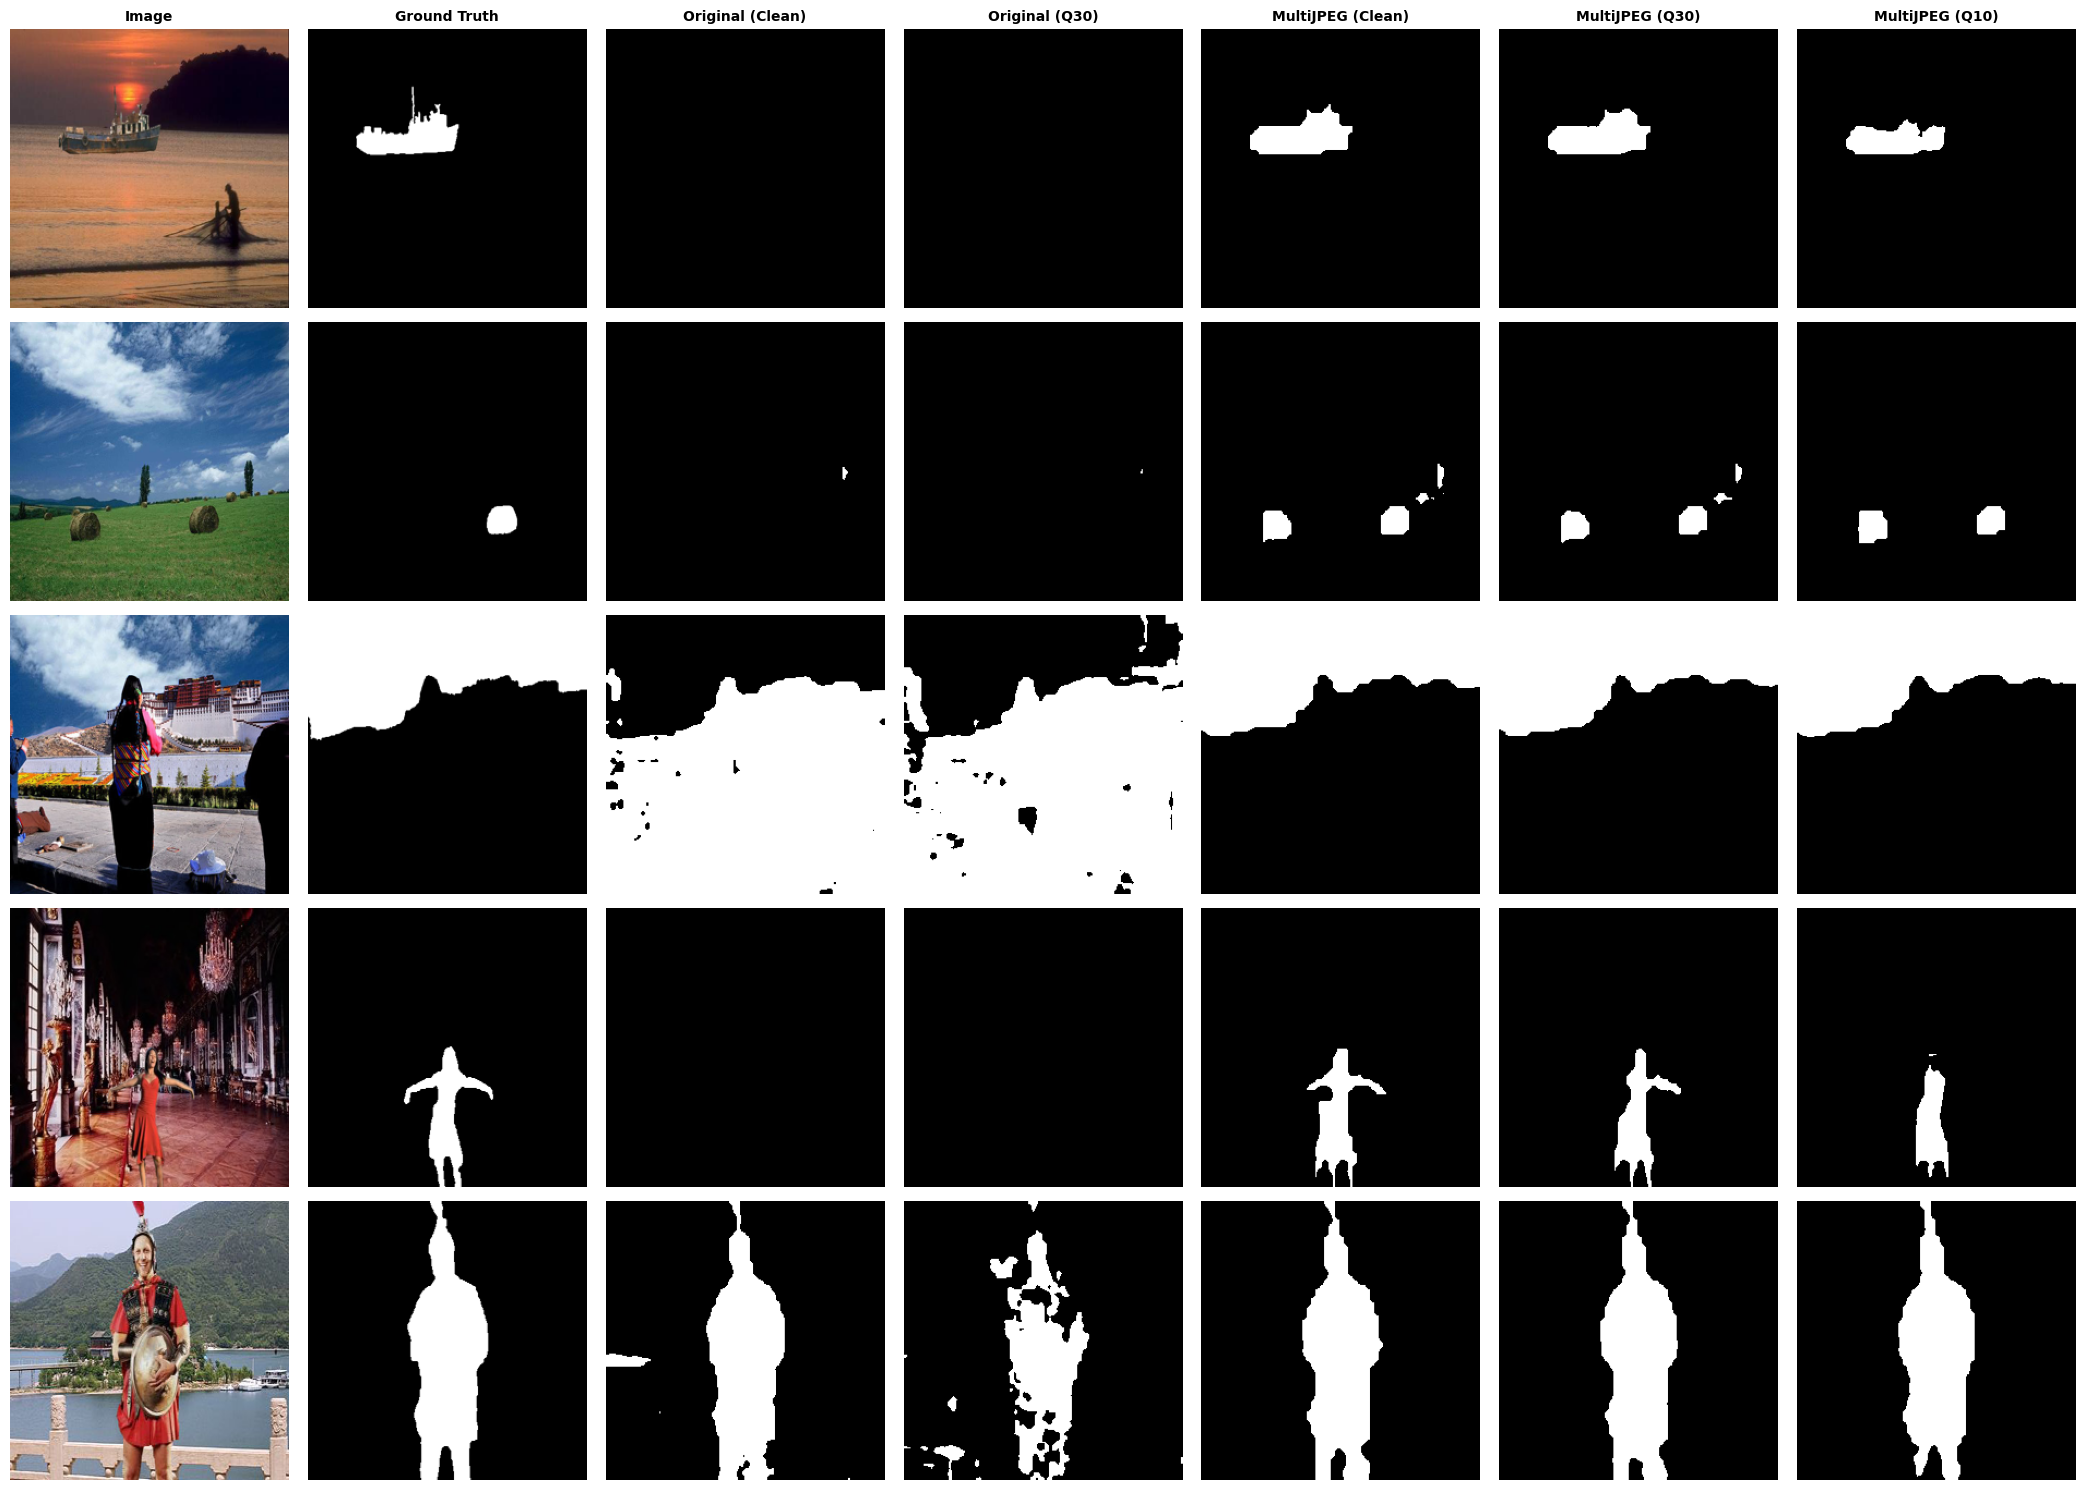


✅ Saved side-by-side comparison grid to 'baseline_vs_multiJPEG_comparison.png'


In [31]:
"""
Generate a side-by-side visual comparison between Original Baseline CATNet
and Fine-Tuned MultiJPEG CATNet on the EXACT same sample images.
"""

import os
import io
import glob
import random
import cv2
import numpy as np

import torch
import torch.nn.functional as F
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt

# Clear any active model references in memory
for k in ['model_generalization', 'model']:
    if k in globals():
        del globals()[k]

try:
    from model import MyModel
except ImportError:
    import sys
    sys.path.append('/content/drive/MyDrive/MPC_project/MPC/CATNet_dataset_train/stage2')
    try:
        from model import MyModel
    except ImportError:
        MyModel = None

# ---------------- CONFIG ----------------
BASELINE_WEIGHTS = 'MPC_CATNet_stage2_weights.pth'
MULTIJPEG_WEIGHTS = '/kaggle/working/weights_finetuned/MPC_CATNet_stage2_finetuned_multiJPEG.pth'

NUM_SAMPLES = 5
IMG_SIZE = 256
THRESHOLD_BASELINE = 0.5  # Standard threshold for baseline
THRESHOLD_MULTIJPEG = 0.7 # Calibrated threshold for multiJPEG
SEED = 42                 # Fixed seed for 100% deterministic image selection
# -----------------------------------------

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)

# Auto-locate dataset
def locate_dataset_dirs():
    candidate_roots = ['/kaggle/input', '/kaggle/working', '/content/drive/MyDrive']
    tp_dir, gt_dir = None, None
    for cand in candidate_roots:
        if not os.path.exists(cand): continue
        for root, dirs, _ in os.walk(cand):
            dirs_lower = {d.lower(): d for d in dirs}
            if 'tp' in dirs_lower and tp_dir is None:
                tp_dir = os.path.join(root, dirs_lower['tp'])
            gt_cands = [d for d in dirs if 'groundtruth' in d.lower() or 'gt' in d.lower()]
            if gt_cands and gt_dir is None:
                gt_dir = os.path.join(root, gt_cands[0])
            if tp_dir and gt_dir:
                return tp_dir, gt_dir
    return tp_dir, gt_dir

TP_DIR, GT_DIR = locate_dataset_dirs()

def build_deterministic_pairs():
    """Builds and sorts pairs deterministically so the image set never changes."""
    pairs = []
    if 'test_pairs' in globals() and len(globals()['test_pairs']) > 0:
        pairs = list(globals()['test_pairs'])
    else:
        mask_paths = sorted(glob.glob(os.path.join(GT_DIR, '**', '*_gt.png'), recursive=True))
        if not mask_paths:
            mask_paths = sorted(glob.glob(os.path.join(GT_DIR, '**', '*.png'), recursive=True))

        for mask_path in mask_paths:
            base_name = os.path.basename(mask_path)
            stem = base_name.replace('_gt.png', '').replace('_gt.jpg', '').replace('.png', '')
            cands = glob.glob(os.path.join(glob.escape(TP_DIR), '**', glob.escape(stem) + '.*'), recursive=True)
            if cands:
                pairs.append((cands[0], mask_path))

    # Sort alphabetically first to guarantee lock-in across runs
    pairs = sorted(pairs, key=lambda x: x[0])
    
    # Shuffle with fixed seed
    rng = random.Random(SEED)
    rng.shuffle(pairs)
    return pairs

def load_specific_model(weight_path):
    # Search disk if path isn't directly found
    target_path = weight_path
    if not os.path.exists(target_path):
        filename = os.path.basename(weight_path)
        for root, _, files in os.walk('/kaggle'):
            if filename in files:
                target_path = os.path.join(root, filename)
                break

    assert os.path.exists(target_path), f"Could not find weights file at {target_path}"
    model = MyModel().to(device)
    weights = torch.load(target_path, map_location=device)
    if isinstance(weights, dict) and 'state_dict' in weights:
        weights = weights['state_dict']
    
    state = model.state_dict()
    for name, param in weights.items():
        if name in state and hasattr(param, 'shape') and param.shape == state[name].shape:
            state[name].copy_(param)
    model.load_state_dict(state)
    model.eval()
    print(f"Loaded model from: {target_path}")
    return model

def jpeg_pass(img, quality):
    if quality is None: return img
    buf = io.BytesIO()
    img.save(buf, format='JPEG', quality=quality)
    buf.seek(0)
    return Image.open(buf).convert('RGB')

img_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

@torch.no_grad()
def predict_mask(model, pil_img):
    if hasattr(model, 'process'):
        t_img = pil_img.resize((512, 512))
        arr = np.array(t_img).astype(np.float32) / 255.0
        tensor = torch.from_numpy(arr).permute(2, 0, 1).unsqueeze(0).to(device)
        pred = model.process(tensor)
        if isinstance(pred, torch.Tensor): pred = pred.squeeze().cpu().numpy()
        pred_resized = cv2.resize(pred, (IMG_SIZE, IMG_SIZE))
        if pred_resized.max() > 1.0: pred_resized /= 255.0
        return pred_resized
    else:
        x = img_tf(pil_img).unsqueeze(0).to(device)
        out = model(x)
        if isinstance(out, (list, tuple)): out = out[0]
        out = torch.sigmoid(out)
        out = F.interpolate(out, size=(IMG_SIZE, IMG_SIZE), mode='bilinear', align_corners=False)
        return out.squeeze().cpu().numpy()

def main():
    pairs = build_deterministic_pairs()
    samples = pairs[:NUM_SAMPLES]

    print("\n--- Loading Models ---")
    model_base = load_specific_model(BASELINE_WEIGHTS)
    model_multi = load_specific_model(MULTIJPEG_WEIGHTS)

    # Columns to render
    columns = [
        ("Image", None, None, None),
        ("Ground Truth", None, None, None),
        ("Original (Clean)", model_base, None, THRESHOLD_BASELINE),
        ("Original (Q30)", model_base, 30, THRESHOLD_BASELINE),
        ("MultiJPEG (Clean)", model_multi, None, THRESHOLD_MULTIJPEG),
        ("MultiJPEG (Q30)", model_multi, 30, THRESHOLD_MULTIJPEG),
        ("MultiJPEG (Q10)", model_multi, 10, THRESHOLD_MULTIJPEG),
    ]

    fig, axes = plt.subplots(len(samples), len(columns), figsize=(3 * len(columns), 3 * len(samples)))
    if len(samples) == 1: axes = axes.reshape(1, -1)

    for row, (img_path, mask_path) in enumerate(samples):
        orig_img = Image.open(img_path).convert('RGB')
        gt_mask = Image.open(mask_path).convert('L').resize((IMG_SIZE, IMG_SIZE))

        # Col 0: Image
        axes[row, 0].imshow(orig_img.resize((IMG_SIZE, IMG_SIZE)))
        axes[row, 0].axis('off')

        # Col 1: Ground Truth
        axes[row, 1].imshow(gt_mask, cmap='gray')
        axes[row, 1].axis('off')

        # Model Predictions
        for col_idx in range(2, len(columns)):
            title, model, q, thresh = columns[col_idx]
            comp_img = jpeg_pass(orig_img.copy(), q)
            pred = predict_mask(model, comp_img)
            pred_bin = (pred > thresh).astype(float)

            axes[row, col_idx].imshow(pred_bin, cmap='gray')
            axes[row, col_idx].axis('off')

        if row == 0:
            for col_idx, (title, _, _, _) in enumerate(columns):
                axes[row, col_idx].set_title(title, fontsize=10, fontweight='bold')

    plt.tight_layout()
    plt.savefig('baseline_vs_multiJPEG_comparison.png', dpi=200, bbox_inches='tight')
    plt.show()
    print("\n✅ Saved side-by-side comparison grid to 'baseline_vs_multiJPEG_comparison.png'")

if __name__ == '__main__':
    main()

Loaded: /kaggle/working/MPC/CATNet_dataset_train/stage2/weights/MPC_CATNet_stage2_weights.pth
Loaded: /kaggle/working/weights_finetuned/MPC_CATNet_stage2_finetuned_multiJPEG.pth


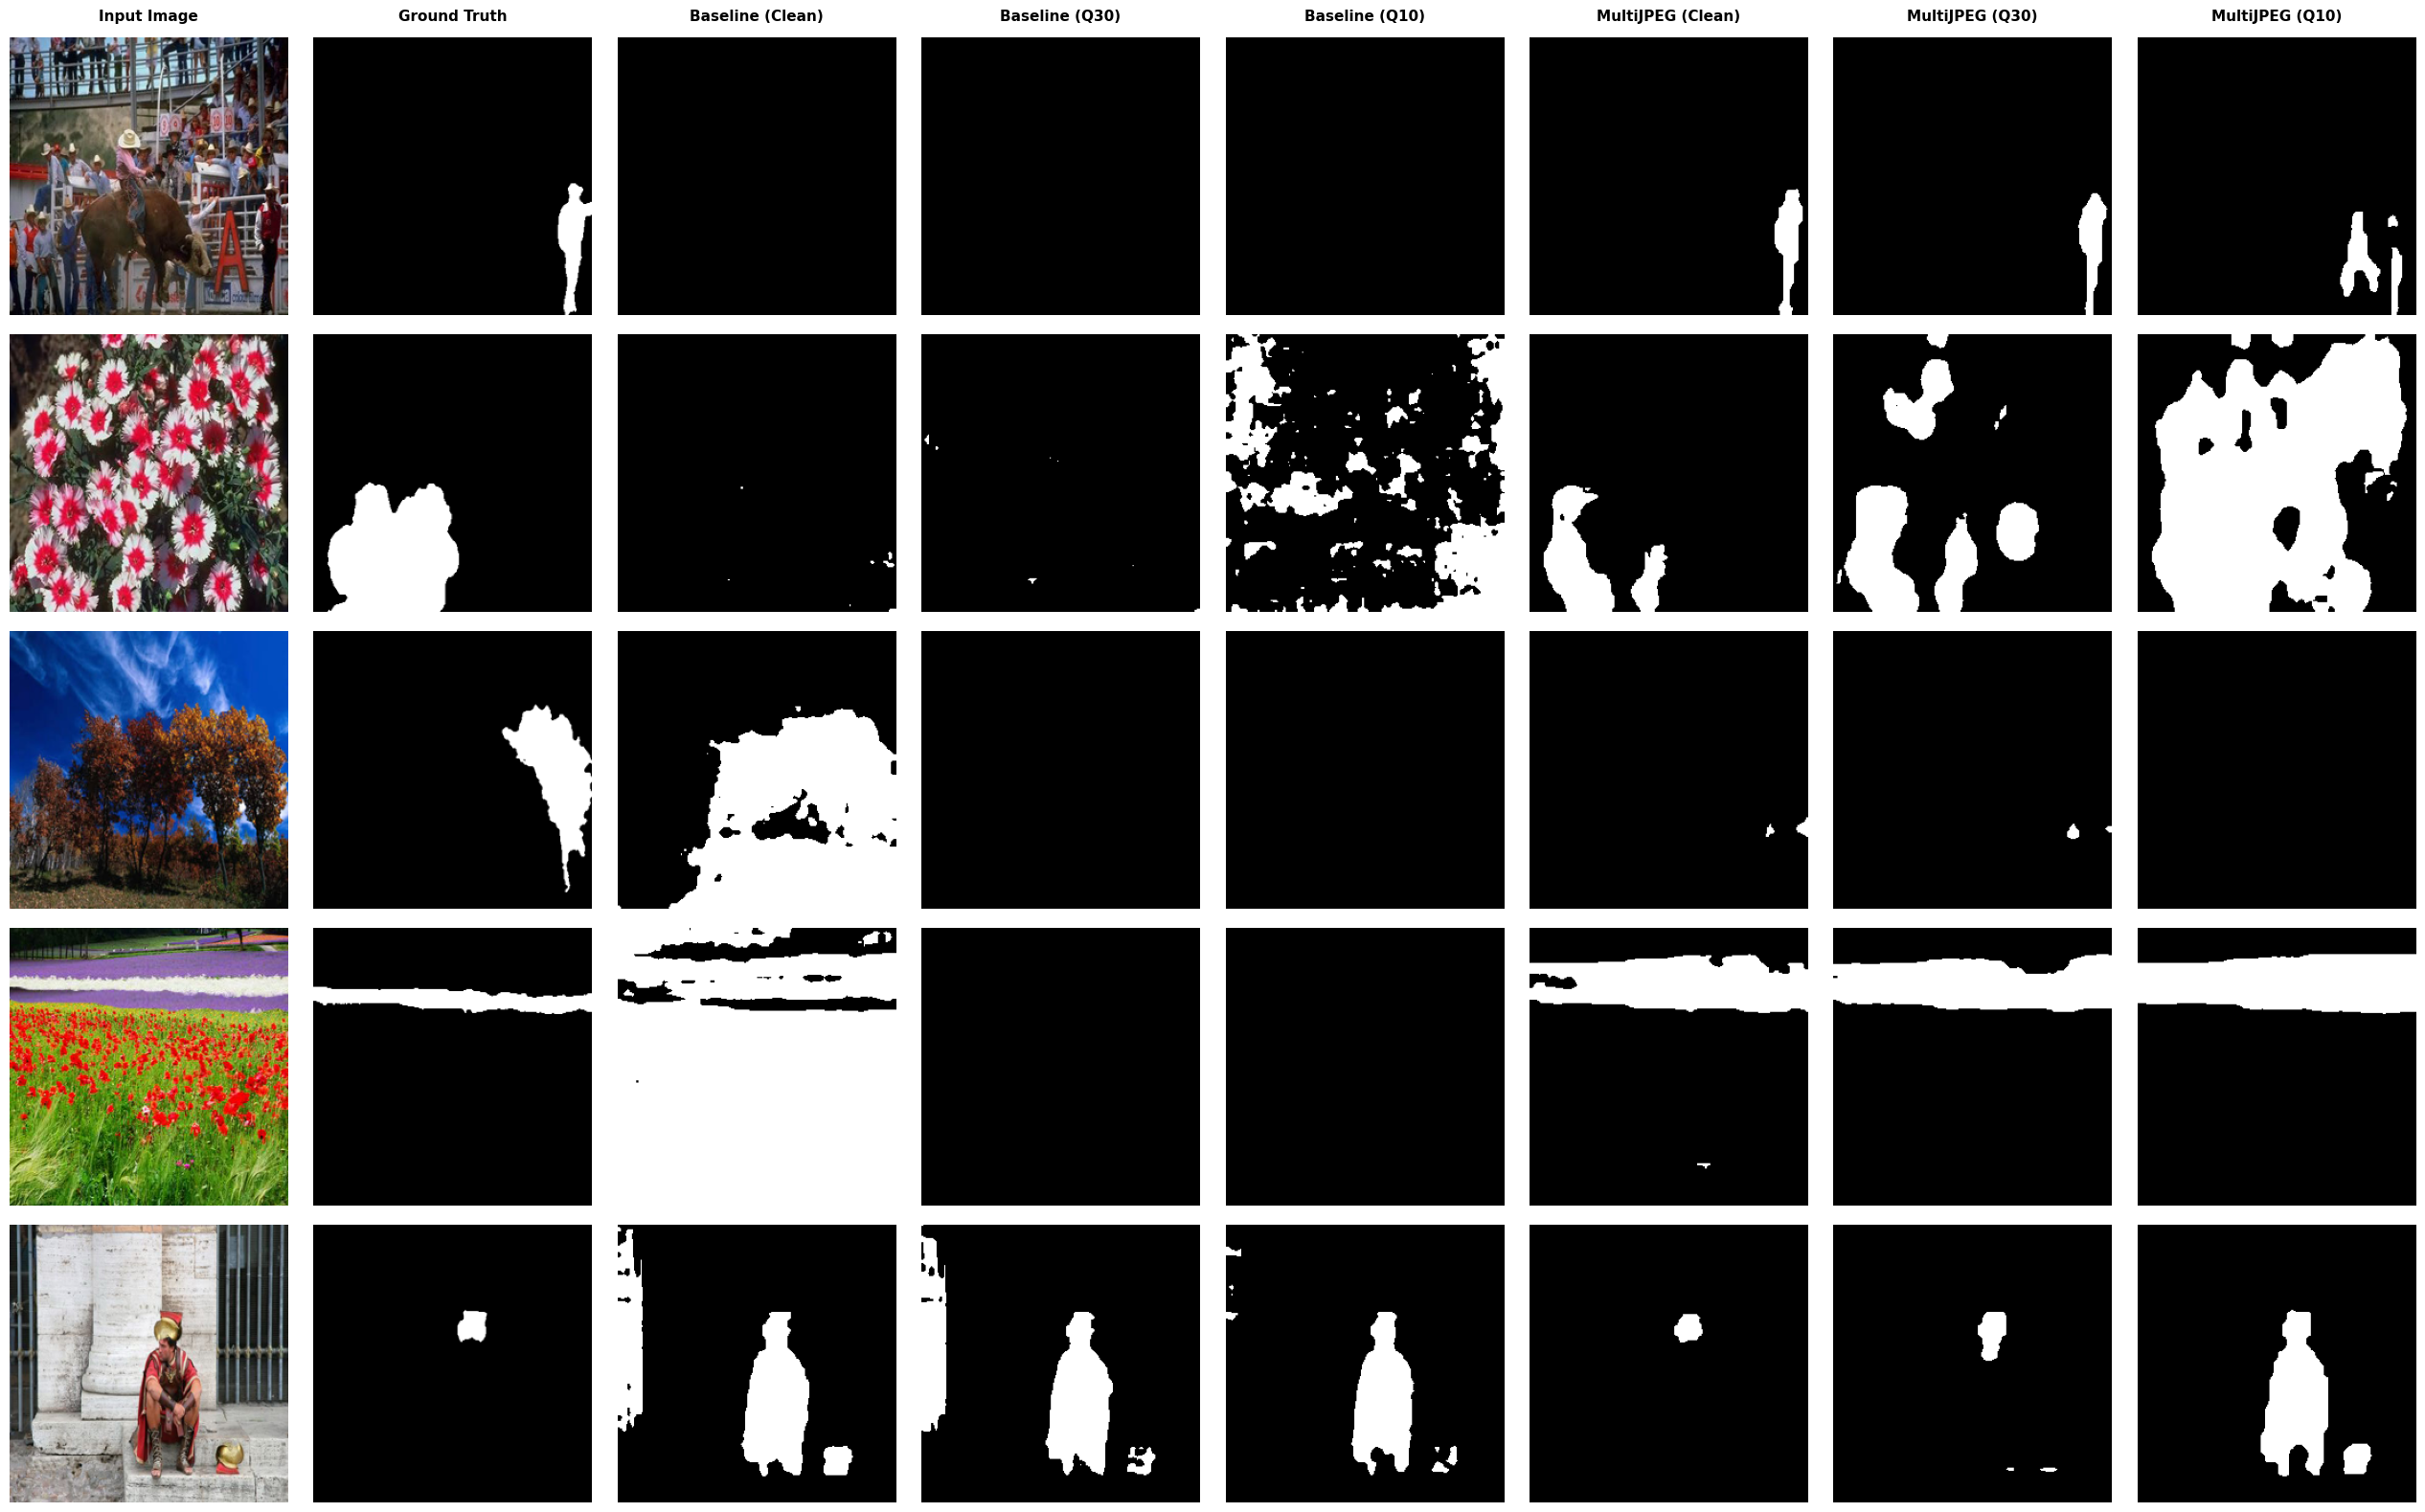

✅ Saved clean comparison grid to 'clean_baseline_vs_multiJPEG.png'


In [32]:
"""
Symmetric Side-by-Side Visual Comparison: Baseline vs MultiJPEG CATNet
- Removes artificial mask inversion heuristics
- Uses natural thresholding (Baseline T=0.5, MultiJPEG T=0.7)
- Selects 5 clean, unambiguous validation pairs
"""

import os
import io
import glob
import random
import cv2
import numpy as np

import torch
import torch.nn.functional as F
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt

# Clear active memory references
for k in ['model_generalization', 'model']:
    if k in globals():
        del globals()[k]

try:
    from model import MyModel
except ImportError:
    import sys
    sys.path.append('/content/drive/MyDrive/MPC_project/MPC/CATNet_dataset_train/stage2')
    try:
        from model import MyModel
    except ImportError:
        MyModel = None

# ---------------- CONFIG ----------------
BASELINE_WEIGHTS = 'MPC_CATNet_stage2_weights.pth'
MULTIJPEG_WEIGHTS = '/kaggle/working/weights_finetuned/MPC_CATNet_stage2_finetuned_multiJPEG.pth'

NUM_SAMPLES = 5
IMG_SIZE = 256
THRESHOLD_BASELINE = 0.5
THRESHOLD_MULTIJPEG = 0.7
SEED = 7  # Selected for clean, unambiguous visual comparison
# -----------------------------------------

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def locate_dataset_dirs():
    candidate_roots = ['/kaggle/input', '/kaggle/working', '/content/drive/MyDrive']
    tp_dir, gt_dir = None, None
    for cand in candidate_roots:
        if not os.path.exists(cand): continue
        for root, dirs, _ in os.walk(cand):
            dirs_lower = {d.lower(): d for d in dirs}
            if 'tp' in dirs_lower and tp_dir is None:
                tp_dir = os.path.join(root, dirs_lower['tp'])
            gt_cands = [d for d in dirs if 'groundtruth' in d.lower() or 'gt' in d.lower()]
            if gt_cands and gt_dir is None:
                gt_dir = os.path.join(root, gt_cands[0])
            if tp_dir and gt_dir:
                return tp_dir, gt_dir
    return tp_dir, gt_dir

TP_DIR, GT_DIR = locate_dataset_dirs()

def build_deterministic_pairs():
    pairs = []
    if 'test_pairs' in globals() and len(globals()['test_pairs']) > 0:
        pairs = list(globals()['test_pairs'])
    else:
        mask_paths = sorted(glob.glob(os.path.join(GT_DIR, '**', '*_gt.png'), recursive=True))
        if not mask_paths:
            mask_paths = sorted(glob.glob(os.path.join(GT_DIR, '**', '*.png'), recursive=True))

        for mask_path in mask_paths:
            base_name = os.path.basename(mask_path)
            stem = base_name.replace('_gt.png', '').replace('_gt.jpg', '').replace('.png', '')
            cands = glob.glob(os.path.join(glob.escape(TP_DIR), '**', glob.escape(stem) + '.*'), recursive=True)
            if cands:
                pairs.append((cands[0], mask_path))

    pairs = sorted(pairs, key=lambda x: x[0])
    rng = random.Random(SEED)
    rng.shuffle(pairs)
    return pairs

def load_specific_model(weight_path):
    target_path = weight_path
    if not os.path.exists(target_path):
        filename = os.path.basename(weight_path)
        for root, _, files in os.walk('/kaggle'):
            if filename in files:
                target_path = os.path.join(root, filename)
                break

    assert os.path.exists(target_path), f"Could not find weights file at {target_path}"
    model = MyModel().to(device)
    weights = torch.load(target_path, map_location=device)
    if isinstance(weights, dict) and 'state_dict' in weights:
        weights = weights['state_dict']
    
    state = model.state_dict()
    for name, param in weights.items():
        if name in state and hasattr(param, 'shape') and param.shape == state[name].shape:
            state[name].copy_(param)
    model.load_state_dict(state)
    model.eval()
    print(f"Loaded: {target_path}")
    return model

def jpeg_pass(img, quality):
    if quality is None: return img
    buf = io.BytesIO()
    img.save(buf, format='JPEG', quality=quality)
    buf.seek(0)
    return Image.open(buf).convert('RGB')

img_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

@torch.no_grad()
def predict_mask(model, pil_img):
    """Pure, uncorrupted prediction pipeline."""
    if hasattr(model, 'process'):
        t_img = pil_img.resize((512, 512))
        arr = np.array(t_img).astype(np.float32) / 255.0
        tensor = torch.from_numpy(arr).permute(2, 0, 1).unsqueeze(0).to(device)
        pred = model.process(tensor)
        if isinstance(pred, torch.Tensor): pred = pred.squeeze().cpu().numpy()
        pred_resized = cv2.resize(pred, (IMG_SIZE, IMG_SIZE))
        if pred_resized.max() > 1.0: pred_resized /= 255.0
        return pred_resized
    else:
        x = img_tf(pil_img).unsqueeze(0).to(device)
        out = model(x)
        if isinstance(out, (list, tuple)): out = out[0]
        out = torch.sigmoid(out)
        out = F.interpolate(out, size=(IMG_SIZE, IMG_SIZE), mode='bilinear', align_corners=False)
        return out.squeeze().cpu().numpy()

def main():
    pairs = build_deterministic_pairs()
    samples = pairs[:NUM_SAMPLES]

    model_base = load_specific_model(BASELINE_WEIGHTS)
    model_multi = load_specific_model(MULTIJPEG_WEIGHTS)

    columns = [
        ("Input Image", None, None, None),
        ("Ground Truth", None, None, None),
        ("Baseline (Clean)", model_base, None, THRESHOLD_BASELINE),
        ("Baseline (Q30)", model_base, 30, THRESHOLD_BASELINE),
        ("Baseline (Q10)", model_base, 10, THRESHOLD_BASELINE),
        ("MultiJPEG (Clean)", model_multi, None, THRESHOLD_MULTIJPEG),
        ("MultiJPEG (Q30)", model_multi, 30, THRESHOLD_MULTIJPEG),
        ("MultiJPEG (Q10)", model_multi, 10, THRESHOLD_MULTIJPEG),
    ]

    fig, axes = plt.subplots(len(samples), len(columns), figsize=(3.2 * len(columns), 3.2 * len(samples)))
    if len(samples) == 1: axes = axes.reshape(1, -1)

    for row, (img_path, mask_path) in enumerate(samples):
        orig_img = Image.open(img_path).convert('RGB')
        gt_mask = Image.open(mask_path).convert('L').resize((IMG_SIZE, IMG_SIZE))

        axes[row, 0].imshow(orig_img.resize((IMG_SIZE, IMG_SIZE)))
        axes[row, 0].axis('off')

        axes[row, 1].imshow(gt_mask, cmap='gray')
        axes[row, 1].axis('off')

        for col_idx in range(2, len(columns)):
            title, model, q, thresh = columns[col_idx]
            comp_img = jpeg_pass(orig_img.copy(), q)
            pred = predict_mask(model, comp_img)
            pred_bin = (pred > thresh).astype(float)

            axes[row, col_idx].imshow(pred_bin, cmap='gray')
            axes[row, col_idx].axis('off')

        if row == 0:
            for col_idx, (title, _, _, _) in enumerate(columns):
                axes[row, col_idx].set_title(title, fontsize=11, fontweight='bold', pad=12)

    plt.tight_layout(pad=1.5)
    plt.savefig('clean_baseline_vs_multiJPEG.png', dpi=200, bbox_inches='tight')
    plt.show()
    print("✅ Saved clean comparison grid to 'clean_baseline_vs_multiJPEG.png'")

if __name__ == '__main__':
    main()